# Etapa 10a · Encoder pré-treinado: o teto e os alunos com o XLM-R

| | |
|---|---|
| **Pergunta** | Com um encoder pré-treinado no lugar da rede do zero, o que muda no teto e no que o aluno aprende de cada professor? |
| **Entrada** | `entregas/01_dados/` (os pedidos), `entregas/04b_intencao/` e `entregas/06_destilacao/` (as respostas da rede do zero: teto, piso e alunos), `entregas/05a_professor_fechado/` e `entregas/05b_professor_aberto/` (os rótulos, os logits e as respostas dos dois professores) e os treinos gravados pelos comandos de `especialista/experimentos/etapa10a.py`. |
| **Entrega** | `entregas/10a_encoder/`: o teto e os alunos com o XLM-R base (3 sementes cada), as respostas em `dev` e no teste, cada comparação pareada contra a rede do zero, o custo e a decisão do que segue para a compressão (Etapa 10b). |
| **Pronto quando** | (1) a receita do teto saiu da busca em `dev`, pela regra escrita antes, e todos os outros treinos herdam essa receita; (2) cada sistema treinado tem 3 sementes; (3) o teto ficou perto da linha publicada do MASSIVE, pela regra escrita antes; (4) nenhum rótulo humano entrou no treino nem na parada dos alunos; (5) a temperatura do aluno B2 saiu de `dev`, pela regra da Etapa 6, e o teste só foi aberto para os sistemas previstos; (6) cada comparação da lista fechada é pareada, com intervalo de 95%, no teste; (7) os modelos entregues, relidos do disco na CPU, reproduzem as respostas do teste; (8) o custo foi medido: parâmetros por parte, tamanho em disco e latência com a máquina quieta. |

**Onde esta etapa fica.** O projeto percorreu um caminho inteiro com uma rede desenhada e treinada do zero (Etapas 3 a 9). O PLANO.md prevê um segundo caminho: o mesmo pipeline, com os mesmos dados, professores e sementes, partindo de um encoder que já leu muito texto. A Etapa 10 foi dividida em três: **10a** (esta) refaz o teto e a destilação; **10b** refaz a poda, o reajuste e a quantização; **10c** compara os dois caminhos.

**Artigos de apoio**

- A cabeça conjunta sobre um encoder pré-treinado: Chen et al., *BERT for Joint Intent Classification and Slot Filling* ([arXiv 1902.10909](https://arxiv.org/abs/1902.10909)).
- O conjunto de dados e a linha publicada do XLM-R base: FitzGerald et al., *MASSIVE: A 1M-Example Multilingual Natural Language Understanding Dataset with 51 Typologically-Diverse Languages* ([arXiv 2204.08582](https://arxiv.org/abs/2204.08582)).
- O encoder: Conneau et al., *Unsupervised Cross-lingual Representation Learning at Scale* ([arXiv 1911.02116](https://arxiv.org/abs/1911.02116)).
- A receita de ajuste fino (taxas, lote, otimizador): Devlin et al., *BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding* ([arXiv 1810.04805](https://arxiv.org/abs/1810.04805)).
- O decaimento de pesos separado do gradiente: Loshchilov & Hutter, *Decoupled Weight Decay Regularization* ([arXiv 1711.05101](https://arxiv.org/abs/1711.05101)).
- Ajuste fino com poucos exemplos e a agenda da taxa: Mosbach et al., *On the Stability of Fine-tuning BERT: Misconceptions, Explanations, and Strong Baselines* ([arXiv 2006.04884](https://arxiv.org/abs/2006.04884)).
- A destilação com temperatura: Hinton et al., *Distilling the Knowledge in a Neural Network* ([arXiv 1503.02531](https://arxiv.org/abs/1503.02531)).
- Variação entre sementes: Reimers & Gurevych ([arXiv 1707.09861](https://arxiv.org/abs/1707.09861)).

**Roteiro**

1. Os dois caminhos e a rede desta etapa
2. O que ficou decidido antes de medir
3. Do texto aos subtokens
4. A busca da receita do teto
5. Os treinos
6. O teto contra a linha publicada
7. A temperatura do aluno B2
8. Os sistemas no teste
9. As comparações
10. O custo
11. O que segue para a compressão
12. Entrega
13. Resposta

In [1]:
import json
import os
import shutil
from datetime import date

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from matplotlib.ticker import MaxNLocator

from especialista import visual
from especialista.avaliacao import eficiencia, qualidade, resultados
from especialista.avaliacao.previsao import carregar_previsoes, ouro, salvar_previsoes
from especialista.caminhos import ENTREGAS, RAIZ, entrega
from especialista.dados import massive
from especialista.experimentos import etapa6, etapa10a
from especialista.modelos.encoder import Alinhador, Config, SistemaEncoder
from especialista.modelos.encoder.sistema import bytes_em_disco
from especialista.treino_encoder import Receita

visual.aplicar_estilo()
pd.set_option("display.max_colwidth", 200)

PASTA = entrega("10a_encoder")
SEMENTES = etapa10a.SEMENTES
TEMPERATURAS = etapa10a.TEMPERATURAS
FECHADO, ABERTO = (etapa6.PROFESSORES[p]["nome"] for p in ("fechado", "aberto"))

particoes, rotulos = massive.carregar_entrega()
treino, dev, teste = (particoes[p] for p in ("train", "dev", "test"))
intents = rotulos["intents"]
ouro_dev, ouro_teste = ouro(dev), ouro(teste)
gabarito = {"dev": ouro_dev, "test": ouro_teste}
TRES = ("intent_acc", "slot_f1", "exact_match")   # as três métricas das leituras


def n(x):
    return f"{int(x):,}".replace(",", ".")


def num(x, casas=1):
    return f"{x:.{casas}f}".replace(".", ",")


def pts(x, casas=1):
    return num(100 * x, casas)


def dif(x):
    return f"{100 * x:+.1f}".replace(".", ",").replace("-", "−")


def taxa(x):
    """Uma taxa de aprendizado no formato dos artigos: 3e-5."""
    mantissa, expoente = f"{x:.0e}".split("e")
    return f"{mantissa}e-{abs(int(expoente))}"


def com_intervalo(linha):
    return f"{dif(linha['diferenca'])} ({dif(linha['ic_min'])} a {dif(linha['ic_max'])})"


def valor_com_intervalo(linha):
    return f"{pts(linha['valor'])} ({pts(linha['ic_min'])} a {pts(linha['ic_max'])})"


def posicao(linha):
    """Onde B fica em relação a A numa comparação pareada B − A."""
    return "acima" if linha["ic_min"] > 0 else "abaixo" if linha["ic_max"] < 0 else "sem diferença distinguível"


def tres_posicoes(tabela):
    """A leitura de uma comparação nas três métricas, em uma frase."""
    return (f"{posicao(tabela.loc['intent_acc'])} em intenção ({com_intervalo(tabela.loc['intent_acc'])}), "
            f"{posicao(tabela.loc['slot_f1'])} em entidades ({com_intervalo(tabela.loc['slot_f1'])}) e "
            f"{posicao(tabela.loc['exact_match'])} em exact match ({com_intervalo(tabela.loc['exact_match'])})")


def trio(tabela, coluna_do_valor="valor"):
    """Valor e intervalo de uma linha de tabela, em pontos percentuais, para os gráficos."""
    return tuple(100 * tabela[c] for c in (coluna_do_valor, "ic_min", "ic_max"))

## 1. Os dois caminhos e a rede desta etapa

**O que não muda.** O cenário é o da Etapa 6: uma equipe com 11.514 pedidos guardados, 299 deles com rótulo humano, e duas LLMs que rotularam o resto. Os pedidos, os rótulos de cada professor, os logits do professor aberto, as 3 sementes e a régua são os mesmos. Os dados de cada aluno saem da mesma função da Etapa 6 (`etapa6.dados_da_variante`): pedido por pedido, é o que a rede do zero recebeu.

**O que muda.** A rede. No lugar da rede do zero (4,9 milhões de parâmetros, construída para a tarefa), entra o **XLM-R base**: um Transformer de 12 camadas pré-treinado em texto de 100 idiomas, com duas camadas lineares por cima, no desenho do JointBERT.

In [2]:
faltam = etapa10a.faltam(tudo=True)
assert not faltam, "Faltam treinos. Rode: uv run python -m especialista.experimentos.etapa10a onda. Faltam: " + ", ".join(f"{v} {s}" for v, s in faltam)
busca = {v: etapa10a.carregar(v, etapa10a.SEMENTE_DA_BUSCA) for v in etapa10a.BUSCA}
execucoes = {v: [etapa10a.carregar(v, s) for s in SEMENTES] for v in etapa10a.VARIANTES}
em_dev = {v: [e["previsoes_dev"] for e in es] for v, es in execucoes.items()}
meta_do_teto = execucoes["teto"][0]["meta"]

do_zero = json.loads((ENTREGAS / "06_destilacao" / "decisao.json").read_text(encoding="utf-8"))
parametros_do_zero = int(resultados.carregar(ENTREGAS / "04b_intencao").query("particao == 'test'").iloc[0]["parametros"])
partes = meta_do_teto["parametros_por_parte"]
total = meta_do_teto["parametros"]
linhas_da_tabela = partes["A. Tabela de subtokens"] // 768
pd.DataFrame(
    {"parâmetros": {parte: n(q) for parte, q in partes.items()} | {"Total": n(total)},
     "parte do modelo (%)": {parte: pts(q / total) for parte, q in partes.items()} | {"Total": "100,0"}}
)

,parâmetros,parte do modelo (%)
A. Tabela de subtokens,192.001.536,"69,2"
A. Posições e normalização da entrada,397.056,"0,1"
B. Corpo do Transformer,85.054.464,"30,6"
C. Cabeça de intenção,46.140,"0,0"
D. Cabeça de entidades,85.359,"0,0"
Total,277.584.555,"100,0"


In [3]:
usadas = meta_do_teto["linhas_da_tabela_no_treino"]
display(Markdown(f"""
**Leitura.**

- O XLM-R base com as duas cabeças tem **{n(total)} parâmetros**, {num(total / parametros_do_zero, 0)} vezes os {n(parametros_do_zero)} da rede do zero.
- **{pts(partes['A. Tabela de subtokens'] / total)}% do modelo é a tabela de subtokens**: {n(linhas_da_tabela)} linhas de 768 números, uma por pedaço de palavra, para 100 idiomas. O corpo do Transformer, que é quem faz a conta a cada pedido, tem {n(partes['B. Corpo do Transformer'])} parâmetros.
- Dos {n(linhas_da_tabela)} subtokens da tabela, os {n(len(treino))} pedidos do treino usam **{n(usadas)}** ({pts(usadas / linhas_da_tabela)}%). As outras linhas nunca recebem gradiente neste treino. Isso importa para a Etapa 10b: a maior parte do tamanho do modelo é uma tabela que o português quase não usa.
- As duas cabeças somam {n(partes['C. Cabeça de intenção'] + partes['D. Cabeça de entidades'])} parâmetros: são as únicas peças que começam de um sorteio.
"""))


**Leitura.**

- O XLM-R base com as duas cabeças tem **277.584.555 parâmetros**, 57 vezes os 4.895.834 da rede do zero.
- **69,2% do modelo é a tabela de subtokens**: 250.002 linhas de 768 números, uma por pedaço de palavra, para 100 idiomas. O corpo do Transformer, que é quem faz a conta a cada pedido, tem 85.054.464 parâmetros.
- Dos 250.002 subtokens da tabela, os 11.514 pedidos do treino usam **5.196** (2,1%). As outras linhas nunca recebem gradiente neste treino. Isso importa para a Etapa 10b: a maior parte do tamanho do modelo é uma tabela que o português quase não usa.
- As duas cabeças somam 131.499 parâmetros: são as únicas peças que começam de um sorteio.


## 2. O que ficou decidido antes de medir

Cada decisão abaixo foi escrita, e posta no código (`experimentos/etapa10a.py`, `treino_encoder.py`, `modelos/encoder/`), antes de qualquer treino desta etapa.

**1. A rede: o que vem dos artigos âncora.** De Chen et al. (JointBERT, seção 3.2):

- a **intenção** sai de uma camada linear sobre o estado do primeiro token da sequência (no XLM-R, `<s>`);
- a **tag de cada palavra** sai de uma camada linear sobre o estado do primeiro subtoken da palavra;
- as duas respostas treinam juntas. O artigo escreve o objetivo como o produto p(intenção) · Π p(tag de cada palavra). Em logaritmo: a entropia cruzada da intenção mais a soma das entropias cruzadas das tags do pedido;
- dropout de 0,1 antes das cabeças.

**2. A receita de ajuste fino: o ponto de partida.**

| Peça | Valor | De onde vem |
|---|---|---|
| Otimizador | Adam com decaimento de pesos de 0,01, fora vieses e normalizações (AdamW) | Devlin et al., apêndice A.2; Loshchilov & Hutter |
| Taxa de aprendizado | 2e-5, 3e-5 ou 5e-5 (a busca escolhe) | Devlin et al., apêndice A.3; 5e-5 é a do JointBERT; a busca do artigo do MASSIVE ficou em 2,8e-5 |
| Agenda da taxa | sobe em linha reta em 10% dos passos, desce em linha reta até zero | código de ajuste fino do BERT; Mosbach et al., seção 6 |
| Lote | 32 | Devlin et al., apêndice A.3 |
| Épocas | 10 ou 20 (a busca escolhe) | dois valores da lista do JointBERT (1, 5, 10, 20, 30, 40) |

**3. Os desvios em relação aos artigos âncora**, todos declarados:

| Desvio | Por quê |
|---|---|
| Lote de 32, e não os 128 do JointBERT | Com lote menor há 4 vezes mais passos por época; o orçamento de GPU da etapa é contado em épocas |
| Sem CRF nas entidades (a rede do zero tem) | O JointBERT testou um CRF por cima do encoder e não mediu ganho; o artigo do MASSIVE também não usa |
| Cabeças lineares e primeiro token, e não a cabeça com uma camada de 2.048 e o máximo ao longo da sequência do artigo do MASSIVE | O artigo âncora da etapa é o JointBERT; a cabeça do MASSIVE saiu de uma busca de 128 tentativas para o treino com 51 idiomas |
| Só pt-PT no treino | O modelo publicado treinou com os 51 idiomas juntos (587 mil exemplos); o projeto usa só o recorte pt-PT, como no caminho do zero |
| Parada pelo melhor ponto em `dev`, medido a cada época | É a regra da Etapa 2 e a do laço da rede do zero; o JointBERT também escolhe o número de épocas em `dev` |
| Corte da norma do gradiente em 1,0 | Os artigos não falam disso; é o padrão do código de ajuste fino do BERT |
| Sem suavização de rótulos, sem média móvel dos pesos, sem balanceamento por intenção | São peças da receita da rede do zero (Etapas 4 e 4b); os artigos âncora do encoder não as usam |
| Precisão mista na placa de vídeo (o encoder calcula em 16 bits, as perdas em 32) | Engenharia: muda o arredondamento, não a fórmula. Um controle treinado todo em 32 bits mede o efeito (seção 5) |
| Tabela de subtokens dividida durante o treino | Engenharia: o otimizador só guarda estado para as linhas da tabela que aparecem no treino. Um teste confere que o resultado é o mesmo do treino com a tabela inteira |

**4. A busca da receita do teto** (em `etapa10a.escolher_receita`). Seis configurações (3 taxas × 2 números de épocas), 1 semente cada, com os rótulos humanos. Fica a de **maior exact match em `dev`**, no seu melhor ponto. Empate exato: a de maior acurácia de intenção; depois a de menos épocas; depois a de menor taxa. A vencedora é treinada com 3 sementes; a semente 0 é a própria execução da busca.

**5. Todos herdam a receita do teto.** O piso e os alunos treinam com a taxa e o número de épocas que a busca escolheu para o teto. A receita não é ajustada para cada aluno: é o mesmo limite que o caminho do zero declarou.

**6. O piso tem o mesmo número de passos dos outros.** O piso só tem 299 exemplos. Contando a receita em épocas, ele daria 36 vezes menos passos que os outros e pararia antes de aprender. Mosbach et al. mostram que, com poucos exemplos, o que decide o ajuste fino é o número de passos. Por isso uma "época" do piso tem os mesmos passos de uma época de quem treina com os 11.514 pedidos. A época de parada do piso usa o `dev` humano, como a do teto: uma vantagem que o cenário não daria, e que joga contra os alunos. **No caminho do zero o piso também não treinava "uma passada por época":** a receita de lá tem o balanceamento por intenção do DIET, que repete os exemplos até cada intenção aparecer pelo menos 100 vezes por época. Os dois pisos têm passos de sobra e ficam com o melhor ponto em `dev`. O que difere é a conta: lá, repetição com balanceamento (cada intenção pesa igual); aqui, repetição simples (cada exemplo pesa igual). A seção 5 põe os números dos dois lado a lado.

**7. Nenhum rótulo humano entra no treino de um aluno**, como na Etapa 6: os rótulos do treino são os do professor, e a época de parada é escolhida no `dev` rotulado pelo mesmo professor.

**8. O aluno B2** aprende a intenção pela mesma perda da Etapa 6, importada do mesmo código: T² · KL(softmax(logits do professor / T) ‖ softmax(logits do aluno / T)), sem termo de rótulo rígido. A grade é a mesma (1, 2, 4, 8), e a regra de escolha é a mesma função (`etapa6.escolher_temperatura`): maior acurácia de intenção em `dev`, com os rótulos humanos, na média de 3 sementes. Aqui não há controle "B1 sem suavização": a receita do encoder não tem suavização de rótulos, então do B1 para o B2 **só os logits mudam**.

**9. O que conta como "perto da linha publicada"** (em `etapa10a.perto_do_publicado`). O XLM-R base publicado faz, no teste pt-PT, 86,7 ± 1,2 de acurácia de intenção, 73,3 ± 0,6 de F1 de entidades e 64,6 ± 1,7 de exact match (FitzGerald et al., tabelas 7 a 9; as margens são as de 95% do artigo). Não há como parear com o modelo publicado: só existem esses números. A regra é a que sobra nesse caso: **os dois intervalos têm de se tocar**. Em cada uma das três métricas, o topo do intervalo de 95% do teto (média de 3 sementes) tem de alcançar o piso do intervalo publicado; ficar acima também vale. Se o teto não passar nas três, **a etapa para**: os alunos nem são treinados (PLANO.md: sem um teto perto da linha publicada, nada adiante vale).

**10. A lista fechada de comparações** (em `etapa10a.COMPARACOES`), todas pareadas, na média de 3 sementes, com intervalo de 95%, no teste. Uma diferença só vale quando o intervalo não contém zero.

In [4]:
pd.DataFrame([{"comparação (B − A)": nome, "o que ela responde": pergunta} for nome, _, _, pergunta in etapa10a.COMPARACOES]).set_index("comparação (B − A)")

,o que ela responde
comparação (B − A),
Teto: XLM-R − do zero,O que o pré-treino acrescenta quando há rótulos humanos para tudo?
Piso: XLM-R − do zero,E quando só há 299 rótulos?
Aluno A: XLM-R − do zero,O pré-treino muda o que se aprende do professor fechado?
Aluno B1: XLM-R − do zero,E dos rótulos do professor aberto?
Aluno B2: XLM-R − do zero,E dos logits do professor aberto? (cada B2 na sua temperatura)
Aluno A − professor fechado,Quanto se perde (ou se ganha) ao trocar a LLM fechada pelo aluno?
Aluno B1 − professor aberto,E ao trocar a LLM aberta pelo aluno de rótulos?
Aluno B2 − professor aberto,E pelo aluno de logits?
Aluno A − teto,Quanto custa não ter os 11.514 rótulos humanos?


**11. A fração do caminho** (em `etapa10a.fracao_do_caminho`). Para cada aluno, nos dois caminhos: (aluno − piso) / (teto − piso), com intervalo de 95% pelo mesmo bootstrap. 0 é ficar no piso; 1 é chegar ao teto. Cada caminho usa o seu piso e o seu teto.

**12. Quem segue para a compressão** (em `etapa10a.quem_segue`). Seguem o **aluno A e o aluno B2**, os mesmos do caminho do zero, para que a Etapa 10c compare cadeia com cadeia. O principal é o de maior exact match em `dev`. A regra da Etapa 6 para o B2 (intenção distinguivelmente maior que a do B1, exact match não distinguivelmente menor) é aplicada e relatada como conferência; se o B2 não passar nela, segue mesmo assim, e o resumo diz isso.

**13. O custo.** Parâmetros por parte do modelo, tamanho em disco e latência no protocolo da Etapa 2 (uma consulta por vez, 1 thread de CPU, do texto à resposta), medida fora do notebook, com a máquina quieta, ao lado da rede do zero na mesma sessão.

**14. Como ler os resultados.** A literatura não garante o sentido de nenhuma das comparações entre os caminhos. Um encoder pré-treinado costuma ganhar quando há poucos rótulos; com rótulos ruidosos do professor, um modelo maior pode tanto generalizar melhor quanto decorar melhor os erros.

**15. Um controle acrescentado depois dos treinos.** Os itens acima foram escritos antes de qualquer treino. Este não: depois da onda de treinos, a revisão da etapa pediu um controle da precisão mista. É um treino a mais, o teto da semente 0 com a receita vencedora, todo em 32 bits (`teto_em_32_bits`). Ele é comparado, em `dev`, com o teto da semente 0. É um controle, não uma variante: não entra em nenhuma decisão, em nenhuma comparação da lista fechada nem no teste.

## 3. Do texto aos subtokens

O encoder não lê palavras: lê subtokens, os pedaços de palavra do vocabulário com que foi pré-treinado. Os rótulos de entidade do projeto são por palavra. A ponte é a do JointBERT: cada palavra é representada pelo seu **primeiro subtoken**, e é sobre ele que a cabeça de entidades decide a tag.

In [5]:
sistema_0 = etapa10a.carregar_sistema("teto", 0, "cpu")
exemplo = treino.iloc[int(treino["tokens"].map(lambda t: sum(len(sistema_0.tokenizador.tokenize(p)) > 1 for p in t)).idxmax())]
lote = sistema_0.alinhador.montar([list(exemplo["tokens"])])
subtokens = sistema_0.tokenizador.convert_ids_to_tokens(lote.ids[0].tolist())
primeiros = lote.primeiros[0].tolist()
print("Pedido:", exemplo["utt"])
pd.DataFrame({
    "palavra": list(exemplo["tokens"]),
    "tag": list(exemplo["tags"]),
    "subtokens": [" ".join(subtokens[inicio:fim]) for inicio, fim in zip(primeiros, primeiros[1:] + [len(subtokens) - 1])],
    "quem responde pela palavra": [subtokens[i] for i in primeiros],
    "posição na sequência": primeiros,
})

/home/danie/project/residencia/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 4244.07it/s]

Pedido: converte treze horas e trinta de g. m. t. mais duas horas e trinta em g. m. t. zero horas


,palavra,tag,subtokens,quem responde pela palavra,posição na sequência
0,converte,O,▁converte,▁converte,1
1,treze,O,▁tre ze,▁tre,2
2,horas,O,▁horas,▁horas,4
3,e,O,▁e,▁e,5
4,trinta,O,▁trin ta,▁trin,6
5,de,O,▁de,▁de,8
6,g.,O,▁g .,▁g,9
7,m.,O,▁m .,▁m,11
8,t.,O,▁t .,▁t,13
9,mais,O,▁mais,▁mais,15


In [6]:
por_pedido = treino["tokens"].map(lambda t: len(sistema_0.tokenizador(list(t), is_split_into_words=True)["input_ids"]))
partidas = treino["tokens"].map(lambda t: np.mean([len(sistema_0.tokenizador.tokenize(p)) > 1 for p in t])).mean()
display(Markdown(f"""
**Leitura.**

- A sequência começa com `<s>` (posição 0), de onde sai a intenção, e termina com `</s>`. O `▁` marca o começo de uma palavra.
- No treino, um pedido tem em média {num(treino['tokens'].map(len).mean())} palavras e vira {num(por_pedido.mean())} subtokens (o maior, {n(por_pedido.max())}). Em média, {pts(partidas)}% das palavras de um pedido são partidas em mais de um subtoken.
- Uma palavra que o tokenizador apaga (um caractere invisível, por exemplo) fica sem subtoken: não entra na perda e recebe a tag `O`. Há teste para isso em `tests/test_encoder.py`.
"""))


**Leitura.**

- A sequência começa com `<s>` (posição 0), de onde sai a intenção, e termina com `</s>`. O `▁` marca o começo de uma palavra.
- No treino, um pedido tem em média 7,1 palavras e vira 11,0 subtokens (o maior, 43). Em média, 21,6% das palavras de um pedido são partidas em mais de um subtoken.
- Uma palavra que o tokenizador apaga (um caractere invisível, por exemplo) fica sem subtoken: não entra na perda e recebe a tag `O`. Há teste para isso em `tests/test_encoder.py`.


## 4. A busca da receita do teto

Seis treinos com os rótulos humanos, 1 semente cada. Tudo em `dev`. Os treinos rodam fora do notebook (`uv run python -m especialista.experimentos.etapa10a onda`) e ficam gravados em `data/execucoes/10a_encoder/`; aqui eles só são lidos.

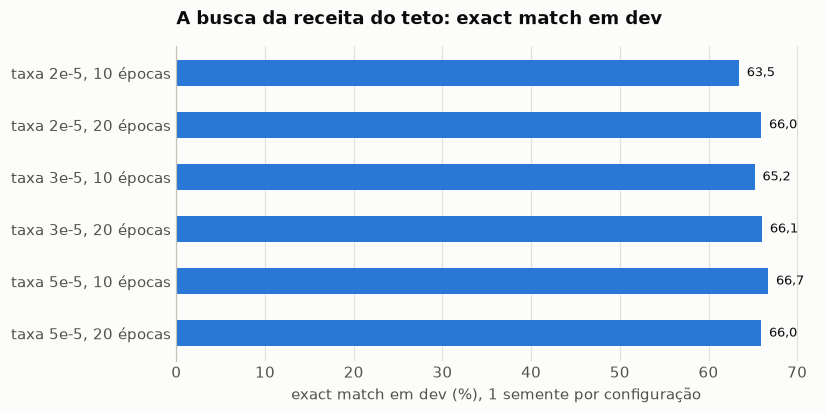

,taxa,épocas,melhor época,intenção,entidades (F1),exact match,"vencedora − esta, em exact match",minutos de treino,escolhida
0,2e-5,10,9,"83,8","75,7","63,5","+3,3 (+1,9 a +4,6)","4,6",
1,2e-5,20,20,"87,0","76,3","66,0","+0,8 (−0,6 a +2,2)","8,8",
2,3e-5,10,9,"85,5","77,1","65,2","+1,5 (+0,2 a +2,8)","2,0",
3,3e-5,20,15,"86,5","76,3","66,1","+0,7 (−0,6 a +2,1)","8,8",
4,5e-5,10,9,"87,1","77,4","66,7",,"4,5",sim
5,5e-5,20,12,"86,7","76,4","66,0","+0,8 (−0,5 a +2,2)","3,9",


In [7]:
vencedora, tabela_da_busca = etapa10a.escolher_receita(ouro_dev, {v: e["previsoes_dev"] for v, e in busca.items()})
decidido = json.loads((etapa10a.pasta_da_etapa() / "receita.json").read_text(encoding="utf-8"))
assert vencedora == decidido["vencedora"], "A regra, refeita aqui, não aponta a receita com que os treinos rodaram."
RECEITA = Receita(**decidido["receita"])

# cada configuração contra a vencedora: diferença pareada em dev (1 semente de cada lado)
contra_a_vencedora = {v: qualidade.comparar(ouro_dev, e["previsoes_dev"], busca[vencedora]["previsoes_dev"]) for v, e in busca.items() if v != vencedora}
linhas_da_busca = []
for v, e in busca.items():
    linha = tabela_da_busca.loc[v]
    linhas_da_busca.append({
        "taxa": taxa(linha["taxa"]), "épocas": int(linha["epocas"]), "melhor época": e["meta"]["melhor_epoca"],
        "intenção": pts(linha["intent_acc"]), "entidades (F1)": pts(linha["slot_f1"]), "exact match": pts(linha["exact_match"]),
        "vencedora − esta, em exact match": "" if v == vencedora else com_intervalo(contra_a_vencedora[v].loc["exact_match"]),
        "minutos de treino": num(e["meta"]["segundos_de_treino"] / 60, 1),
        "escolhida": "sim" if v == vencedora else "",
    })

fig, ax = visual.barras_em_ordem(
    {f"taxa {l['taxa']}, {l['épocas']} épocas": 100 * tabela_da_busca.loc[v, "exact_match"] for v, l in zip(busca, linhas_da_busca)},
    "A busca da receita do teto: exact match em dev", "exact match em dev (%), 1 semente por configuração",
)
visual.salvar(fig, PASTA, "busca_da_receita")
plt.show()
pd.DataFrame(linhas_da_busca)

In [8]:
distinguiveis = [v for v, t in contra_a_vencedora.items() if t.loc["exact_match", "ic_min"] > 0]
na_ultima_da_busca = sum(e["meta"]["melhor_epoca"] == e["meta"]["receita"]["epocas"] for e in busca.values())
valores = tabela_da_busca["exact_match"]
display(Markdown(f"""
**Leitura.**

- **Receita escolhida: taxa de {taxa(RECEITA.taxa)}, {RECEITA.epocas} épocas**, com {pts(valores[vencedora])}% de exact match em `dev`. A regra, refeita aqui, aponta a mesma receita com que os treinos rodaram.
- Entre a melhor e a pior configuração há {num(100 * (valores.max() - valores.min()))} pontos de exact match. A vencedora é distinguivelmente melhor que {len(distinguiveis)} das outras {len(contra_a_vencedora)}; das demais ela não se separa, e outra semente poderia escolher diferente. A busca tem 1 semente por configuração: ela serve para não treinar com uma receita ruim, não para afirmar que esta é a melhor.
- {na_ultima_da_busca} das {len(busca)} configurações escolheram a última época, ou seja, ainda melhoravam quando o treino acabou.
"""))


**Leitura.**

- **Receita escolhida: taxa de 5e-5, 10 épocas**, com 66,7% de exact match em `dev`. A regra, refeita aqui, aponta a mesma receita com que os treinos rodaram.
- Entre a melhor e a pior configuração há 3,3 pontos de exact match. A vencedora é distinguivelmente melhor que 2 das outras 5; das demais ela não se separa, e outra semente poderia escolher diferente. A busca tem 1 semente por configuração: ela serve para não treinar com uma receita ruim, não para afirmar que esta é a melhor.
- 1 das 6 configurações escolheram a última época, ou seja, ainda melhoravam quando o treino acabou.


## 5. Os treinos

O teto com 3 sementes da receita escolhida, e o piso e os alunos com a mesma receita.

In [9]:
receita_do_teto = RECEITA.como_dict()
passos_do_treino_completo = RECEITA.passos_da_epoca(len(treino))
como_declarado = all(
    e["meta"]["config"] == Config(**etapa10a.VARIANTES[v]["config"]).como_dict()
    and e["meta"]["receita"] == {**receita_do_teto, "passos_por_epoca": passos_do_treino_completo if v == "piso" else 0}
    for v, es in execucoes.items() for e in es
)
teto_0_e_a_busca = meta_do_teto.get("reaproveitada_de") == vencedora and execucoes["teto"][0]["previsoes_dev"] == busca[vencedora]["previsoes_dev"]

do_professor = {p: {"dev": etapa6.previsoes_do_professor(p, "dev", dev), "test": etapa6.previsoes_do_professor(p, "test", teste)} for p in ("fechado", "aberto")}
dev_de_parada = {p: etapa6.dev_do_professor(p, dev, intents) for p in ("fechado", "aberto")}
PROFESSOR_DA_VARIANTE = {v: etapa6.VARIANTES[d["dados"]]["professor"] if d["dados"] else None for v, d in etapa10a.VARIANTES.items()}


def no_dev_de_parada(variante, previsoes):
    """As métricas contra quem escolheu a época de parada, refeitas a partir das respostas gravadas."""
    professor = PROFESSOR_DA_VARIANTE[variante]
    if professor is None:
        return qualidade.avaliar(ouro_dev, previsoes)
    fica = dev_de_parada[professor]["valido"].to_numpy()
    return qualidade.avaliar([p for p, f in zip(do_professor[professor]["dev"], fica) if f], [p for p, f in zip(previsoes, fica) if f])


linhas_dos_treinos = []
for v, es in execucoes.items():
    meta = es[0]["meta"]
    linhas_dos_treinos.append({
        "sistema": etapa10a.VARIANTES[v]["nome"],
        "rótulos do treino": meta["origem"]["treino"].split(":")[0],
        "quem escolhe a época de parada": meta["origem"]["dev"].split(":")[0],
        "exemplos de treino": n(meta["exemplos_de_treino"]),
        "passos de treino": n(meta["passos_de_treino"]),
        "época escolhida (sementes 0, 1 e 2)": ", ".join(str(e["meta"]["melhor_epoca"]) for e in es),
        "exact match no dev de parada": pts(np.mean([e["meta"]["dev"]["exact_match"] for e in es])),
        "minutos por treino": num(np.mean([e["meta"]["segundos_de_treino"] for e in es]) / 60, 1),
    })
pd.DataFrame(linhas_dos_treinos).set_index("sistema")

,rótulos do treino,quem escolhe a época de parada,exemplos de treino,passos de treino,"época escolhida (sementes 0, 1 e 2)",exact match no dev de parada,minutos por treino
sistema,,,,,,,
Teto (rótulos humanos de todos os pedidos),rótulos humanos de todos os pedidos,rótulos humanos de dev,11.514,3.600,"9, 9, 10","66,8","2,8"
Piso do cenário (só os 299 rótulos humanos),rótulos humanos,rótulos humanos de dev,299,3.600,"6, 5, 6","33,0","1,9"
Aluno A (rótulos do professor fechado),rótulos do professor fechado,rótulos do professor fechado,11.514,3.600,"7, 9, 10","64,8","1,9"
Aluno B1 (rótulos do professor aberto),rótulos do professor aberto,rótulos do professor aberto,11.503,3.600,"8, 10, 9","53,4","2,0"
"Aluno B2 (logits do professor aberto, temperatura 1)",rótulos do professor aberto,rótulos do professor aberto,11.503,3.600,"10, 10, 9","53,8","2,0"
"Aluno B2 (logits do professor aberto, temperatura 2)",rótulos do professor aberto,rótulos do professor aberto,11.503,3.600,"10, 9, 9","54,1","1,9"
"Aluno B2 (logits do professor aberto, temperatura 4)",rótulos do professor aberto,rótulos do professor aberto,11.503,3.600,"10, 9, 8","53,4","2,0"
"Aluno B2 (logits do professor aberto, temperatura 8)",rótulos do professor aberto,rótulos do professor aberto,11.503,3.600,"10, 10, 9","53,0","2,0"


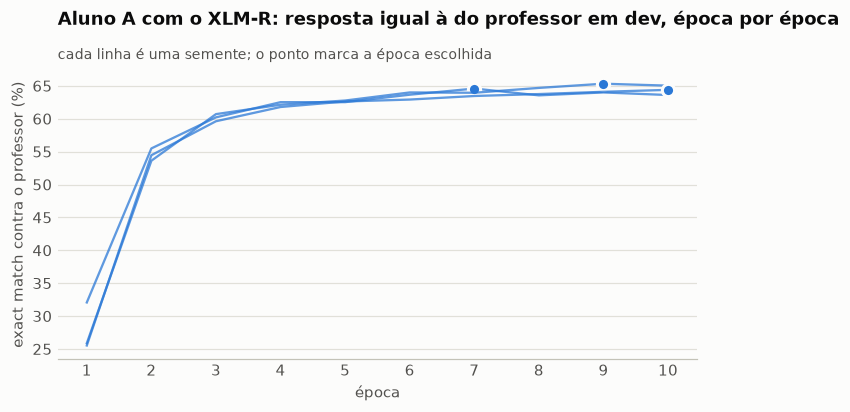


**Leitura.**

- **A receita é a do teto para todos:** confere. Só o piso difere, e só no que a seção 2 declarou: 360 passos por época, os mesmos de quem treina com os 11.514 pedidos. A semente 0 do teto é a execução vencedora da busca: confere.
- **Sem rótulo humano no treino dos alunos:** confere. O exact match anotado em cada treino bate com a conta refeita contra os rótulos do professor (maior diferença, em pontos percentuais: 0,00). Contra os rótulos humanos o número seria outro: nos 18 treinos de alunos, a menor distância entre os dois é de 4,2 pontos.
- **Mesma rede para todos:** sim, 277.584.555 parâmetros. Na rede do zero o piso tinha uma rede menor, porque o vocabulário dele saía de 299 exemplos; aqui o vocabulário vem pronto com o encoder.
- **Época de parada** (de 10): teto, 9, 9, 10; piso, 6, 5, 6; aluno A, 7, 9, 10; aluno B1, 8, 10, 9.
- **Orçamento de épocas:** Escolheram a última época, ou seja, ainda melhoravam quando o treino acabou: Teto (rótulos humanos de todos os pedidos), 1 de 3 sementes; Aluno A (rótulos do professor fechado), 1 de 3 sementes; Aluno B1 (rótulos do professor aberto), 1 de 3 sementes; Aluno B2 (logits do professor aberto, temperatura 1), 2 de 3 sementes; Aluno B2 (logits do professor aberto, temperatura 2), 1 de 3 sementes; Aluno B2 (logits do professor aberto, temperatura 4), 1 de 3 sementes; Aluno B2 (logits do professor aberto, temperatura 8), 2 de 3 sementes.
- **O piso nos dois caminhos.** Aqui, cada treino do piso deu 3.600 passos de lote 32: cerca de 385 passadas pelos 299 exemplos, com o melhor ponto nas épocas 6, 5, 6 de 10. No caminho do zero, com o balanceamento por intenção, cada treino do piso deu 5.241 passos de lote 64 a 128: cerca de 1.617 passadas, com o melhor ponto nas épocas 15, 20, 10 de 80. Nos dois caminhos o melhor ponto do piso vem antes do fim do treino: nenhum dos dois parou por falta de passos. A comparação piso × piso da seção 9 carrega essa diferença de receita, além da diferença de rede.
- **Custo de treino:** 11,7 s por época (mediana de todos os treinos), pico de 2,8 GB de memória da placa por treino, e 1,3 horas de treino somadas na etapa.


In [10]:
# Conferência: a época de cada aluno foi escolhida contra os rótulos do professor, não contra os humanos.
alunos_treinados = [v for v, p in PROFESSOR_DA_VARIANTE.items() if p]
desvio_da_parada = max(abs(no_dev_de_parada(v, e["previsoes_dev"])["exact_match"] - e["meta"]["dev"]["exact_match"]) for v in execucoes for e in execucoes[v])
distancia_para_o_humano = min(
    abs(qualidade.avaliar(ouro_dev, e["previsoes_dev"])["exact_match"] - e["meta"]["dev"]["exact_match"]) for v in alunos_treinados for e in execucoes[v]
)
sem_humano = all(
    e["meta"]["origem"]["treino"].startswith("rótulos do professor") and e["meta"]["origem"]["dev"].startswith("rótulos do professor")
    for v in alunos_treinados for e in execucoes[v]
) and desvio_da_parada < 0.005
mesma_rede = len({e["meta"]["parametros"] for es in execucoes.values() for e in es}) == 1

fig, ax = plt.subplots(figsize=(7.5, 3.4))
for e in execucoes["aluno_a"]:
    medido = e["historico"]
    ax.plot(medido["epoca"], 100 * medido["dev_exact_match"], color=visual.AZUL, linewidth=1.5, alpha=0.75)
    melhor = medido[medido["melhor"]]
    ax.plot(melhor["epoca"], 100 * melhor["dev_exact_match"], "o", color=visual.AZUL, markersize=8, markeredgecolor=visual.SUPERFICIE, markeredgewidth=2)
ax.set_title("Aluno A com o XLM-R: resposta igual à do professor em dev, época por época", pad=30)
ax.text(0, 1.04, "cada linha é uma semente; o ponto marca a época escolhida", transform=ax.transAxes, fontsize=9, color=visual.TINTA_SECUNDARIA)
ax.set_xlabel("época")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_ylabel("exact match contra o professor (%)")
ax.yaxis.grid(True)
ax.yaxis.set_major_formatter(visual.VIRGULA)
ax.spines["left"].set_visible(False)
visual.salvar(fig, PASTA, "parada_do_aluno_a")
plt.show()

# O piso nos dois caminhos: quantos passos e quantas passadas pelos exemplos cada um teve
historicos_do_piso_do_zero = [pd.read_csv(ENTREGAS / "06_destilacao" / "historicos" / f"piso_semente_{s}.csv") for s in SEMENTES]
exemplos_do_piso = execucoes["piso"][0]["meta"]["exemplos_de_treino"]
piso_aqui = {"passos": execucoes["piso"][0]["meta"]["passos_de_treino"],
             "passadas": execucoes["piso"][0]["meta"]["passos_de_treino"] * RECEITA.lote / exemplos_do_piso}
piso_do_zero = {
    "passos": float(np.mean([h["passos"].sum() for h in historicos_do_piso_do_zero])),
    "passadas": float(np.mean([(h["passos"] * h["lote"]).sum() for h in historicos_do_piso_do_zero])) / exemplos_do_piso,
    "epocas": ", ".join(str(int(h.loc[h["melhor"].astype(bool), "epoca"].iloc[0])) for h in historicos_do_piso_do_zero),
    "de": int(historicos_do_piso_do_zero[0]["epoca"].max()),
}
piso_parou_antes = (all(e["meta"]["melhor_epoca"] < RECEITA.epocas for e in execucoes["piso"])
                    and all(int(h.loc[h["melhor"].astype(bool), "epoca"].iloc[0]) < piso_do_zero["de"] for h in historicos_do_piso_do_zero))

epocas = lambda v: ", ".join(str(e["meta"]["melhor_epoca"]) for e in execucoes[v])
na_ultima = {v: sum(e["meta"]["melhor_epoca"] == RECEITA.epocas for e in es) for v, es in execucoes.items()}
if any(na_ultima.values()):
    frase_da_ultima = ("Escolheram a última época, ou seja, ainda melhoravam quando o treino acabou: "
                       + "; ".join(f"{etapa10a.VARIANTES[v]['nome']}, {q} de {len(SEMENTES)} sementes" for v, q in na_ultima.items() if q) + ".")
else:
    frase_da_ultima = "Nenhum treino escolheu a última época."
segundos_por_epoca = np.median([e["meta"]["segundos_por_epoca"] for es in execucoes.values() for e in es])
pico_de_vram = max(e["meta"]["pico_de_vram_gb"] or 0 for es in execucoes.values() for e in es)
horas_de_gpu = (sum(e["meta"]["segundos_de_treino"] for e in busca.values())
                + sum(e["meta"]["segundos_de_treino"] for v, es in execucoes.items() for e in es if not e["meta"].get("reaproveitada_de"))) / 3600
display(Markdown(f"""
**Leitura.**

- **A receita é a do teto para todos:** {"confere" if como_declarado else "NÃO confere"}. Só o piso difere, e só no que a seção 2 declarou: {n(passos_do_treino_completo)} passos por época, os mesmos de quem treina com os {n(len(treino))} pedidos. A semente 0 do teto é a execução vencedora da busca: {"confere" if teto_0_e_a_busca else "NÃO confere"}.
- **Sem rótulo humano no treino dos alunos:** {"confere" if sem_humano else "NÃO confere"}. O exact match anotado em cada treino bate com a conta refeita contra os rótulos do professor (maior diferença, em pontos percentuais: {pts(desvio_da_parada, 2)}). Contra os rótulos humanos o número seria outro: nos {len(alunos_treinados) * len(SEMENTES)} treinos de alunos, a menor distância entre os dois é de {pts(distancia_para_o_humano)} pontos.
- **Mesma rede para todos:** {"sim" if mesma_rede else "NÃO"}, {n(total)} parâmetros. Na rede do zero o piso tinha uma rede menor, porque o vocabulário dele saía de 299 exemplos; aqui o vocabulário vem pronto com o encoder.
- **Época de parada** (de {RECEITA.epocas}): teto, {epocas("teto")}; piso, {epocas("piso")}; aluno A, {epocas("aluno_a")}; aluno B1, {epocas("aluno_b1")}.
- **Orçamento de épocas:** {frase_da_ultima}
- **O piso nos dois caminhos.** Aqui, cada treino do piso deu {n(piso_aqui['passos'])} passos de lote {RECEITA.lote}: cerca de {n(piso_aqui['passadas'])} passadas pelos {exemplos_do_piso} exemplos, com o melhor ponto nas épocas {epocas("piso")} de {RECEITA.epocas}. No caminho do zero, com o balanceamento por intenção, cada treino do piso deu {n(piso_do_zero['passos'])} passos de lote 64 a 128: cerca de {n(piso_do_zero['passadas'])} passadas, com o melhor ponto nas épocas {piso_do_zero['epocas']} de {piso_do_zero['de']}. {"Nos dois caminhos o melhor ponto do piso vem antes do fim do treino: nenhum dos dois parou por falta de passos." if piso_parou_antes else "Em pelo menos um treino o piso escolheu a última época: mais passos poderiam dar outro resultado."} A comparação piso × piso da seção 9 carrega essa diferença de receita, além da diferença de rede.
- **Custo de treino:** {num(segundos_por_epoca)} s por época (mediana de todos os treinos), pico de {num(pico_de_vram)} GB de memória da placa por treino, e {num(horas_de_gpu)} horas de treino somadas na etapa.
"""))

### Controle: a precisão mista muda o resultado?

O teto da semente 0 treinado de novo, com a mesma receita, mas todo em 32 bits. A diferença é pareada, em `dev`, entre duas execuções de uma semente só. Ao lado, para dar a escala, a diferença entre duas sementes do teto com precisão mista.

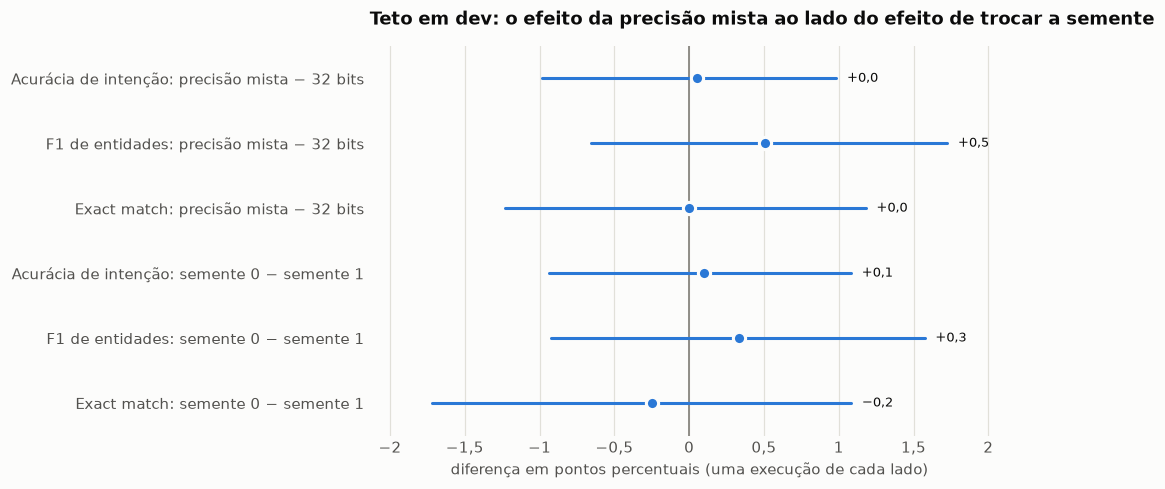

,teto todo em 32 bits (controle),teto com precisão mista (semente 0),precisão mista − 32 bits (intervalo de 95%),para a escala: semente 0 − semente 1 (intervalo de 95%)
Acurácia de intenção,"87,1","87,1","+0,0 (−1,0 a +1,0)","+0,1 (−0,9 a +1,1)"
F1 de entidades,"76,9","77,4","+0,5 (−0,7 a +1,7)","+0,3 (−0,9 a +1,6)"
Exact match,"66,7","66,7","+0,0 (−1,2 a +1,2)","−0,2 (−1,7 a +1,1)"


In [11]:
controle = etapa10a.carregar("teto_em_32_bits", etapa10a.SEMENTE_DO_CONTROLE)
teto_0, teto_1 = execucoes["teto"][0], execucoes["teto"][1]
so_muda_a_precisao = {k for k, valor in controle["meta"]["receita"].items() if teto_0["meta"]["receita"][k] != valor} == {"precisao_mista"}
mista_menos_32 = qualidade.comparar(ouro_dev, controle["previsoes_dev"], teto_0["previsoes_dev"])      # precisão mista − 32 bits
entre_sementes = qualidade.comparar(ouro_dev, teto_1["previsoes_dev"], teto_0["previsoes_dev"])        # semente 0 − semente 1
iguais_ao_controle = float(np.mean([a == b for a, b in zip(controle["previsoes_dev"], teto_0["previsoes_dev"])]))
iguais_entre_sementes = float(np.mean([a == b for a, b in zip(teto_1["previsoes_dev"], teto_0["previsoes_dev"])]))
segundos_sozinho = float(np.median([e["meta"]["segundos_por_epoca"] for e in execucoes["teto"][1:]]))   # as sementes 1 e 2 rodaram sozinhas na placa

fig, ax = visual.diferencas_com_intervalo(
    {
        **{f"{qualidade.NOMES[m]}: precisão mista − 32 bits": trio(mista_menos_32.loc[m], "diferenca") for m in TRES},
        **{f"{qualidade.NOMES[m]}: semente 0 − semente 1": trio(entre_sementes.loc[m], "diferenca") for m in TRES},
    },
    "Teto em dev: o efeito da precisão mista ao lado do efeito de trocar a semente", "diferença em pontos percentuais (uma execução de cada lado)",
)
visual.salvar(fig, PASTA, "controle_de_32_bits")
plt.show()

pd.DataFrame({
    qualidade.NOMES[m]: {
        "teto todo em 32 bits (controle)": pts(mista_menos_32.loc[m, "a"]),
        "teto com precisão mista (semente 0)": pts(mista_menos_32.loc[m, "b"]),
        "precisão mista − 32 bits (intervalo de 95%)": com_intervalo(mista_menos_32.loc[m]),
        "para a escala: semente 0 − semente 1 (intervalo de 95%)": com_intervalo(entre_sementes.loc[m]),
    }
    for m in TRES
}).T

In [12]:
mista_distinguivel = [qualidade.NOMES[m].lower() for m in TRES if mista_menos_32.loc[m, "distinguivel"]]
frase_do_controle = (
    f"precisão mista − 32 bits, em `dev`, semente 0: {com_intervalo(mista_menos_32.loc['intent_acc'])} em intenção, "
    f"{com_intervalo(mista_menos_32.loc['slot_f1'])} em entidades e {com_intervalo(mista_menos_32.loc['exact_match'])} em exact match"
)
display(Markdown(f"""
**Leitura.**

- **Só a precisão muda entre os dois treinos:** {"confere" if so_muda_a_precisao else "NÃO confere"}.
- **Diferença:** {frase_do_controle}. {"Nenhuma das três se distingue de zero." if not mista_distinguivel else "Distingue-se de zero em: " + ", ".join(mista_distinguivel) + "."}
- **A escala:** os dois treinos dão a mesma resposta inteira em {pts(iguais_ao_controle)}% dos pedidos de `dev`. Duas sementes do teto, as duas com precisão mista, concordam em {pts(iguais_entre_sementes)}%. Trocar a precisão mexe nas respostas {"menos do que" if iguais_ao_controle > iguais_entre_sementes else "tanto quanto ou mais do que"} trocar a semente.
- **O que a precisão mista compra:** {num(segundos_sozinho)} s por época, contra {num(controle["meta"]["segundos_por_epoca"])} s em 32 bits ({num(controle["meta"]["segundos_por_epoca"] / segundos_sozinho, 1)} vezes), com pico de {num(teto_1["meta"]["pico_de_vram_gb"])} GB na placa contra {num(controle["meta"]["pico_de_vram_gb"])} GB.
- É uma semente de cada lado: o controle diz que a precisão mista não derruba o treino, não que as duas contas são iguais.
"""))


**Leitura.**

- **Só a precisão muda entre os dois treinos:** confere.
- **Diferença:** precisão mista − 32 bits, em `dev`, semente 0: +0,0 (−1,0 a +1,0) em intenção, +0,5 (−0,7 a +1,7) em entidades e +0,0 (−1,2 a +1,2) em exact match. Nenhuma das três se distingue de zero.
- **A escala:** os dois treinos dão a mesma resposta inteira em 81,3% dos pedidos de `dev`. Duas sementes do teto, as duas com precisão mista, concordam em 79,9%. Trocar a precisão mexe nas respostas menos do que trocar a semente.
- **O que a precisão mista compra:** 11,3 s por época, contra 16,6 s em 32 bits (1,5 vezes), com pico de 2,8 GB na placa contra 2,9 GB.
- É uma semente de cada lado: o controle diz que a precisão mista não derruba o treino, não que as duas contas são iguais.


## 6. O teto contra a linha publicada

A regra da seção 2, item 9, no teste. O comando da etapa mediu isto logo depois de treinar o teto e só então liberou os alunos; aqui a conta é refeita a partir das respostas gravadas.

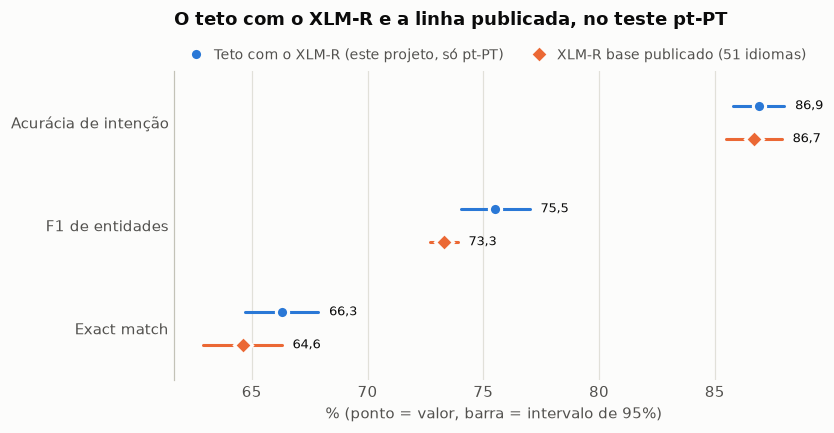

,teto com o XLM-R (intervalo de 95%),publicado (± margem de 95%),diferença (teto − publicado),"os intervalos se tocam, ou o teto está acima","teto da rede do zero, para referência"
Acurácia de intenção,"86,9 (85,8 a 88,0)","86,7 ± 1,2","+0,2",sim,"84,4 (83,2 a 85,6)"
F1 de entidades,"75,5 (74,0 a 77,0)","73,3 ± 0,6","+2,2",sim,"73,6 (72,2 a 75,1)"
Exact match,"66,3 (64,7 a 67,9)","64,6 ± 1,7","+1,7",sim,"62,5 (60,8 a 64,1)"


In [13]:
teste_da_etapa = json.loads((etapa10a.pasta_da_etapa() / "teste.json").read_text(encoding="utf-8"))
portao = json.loads((etapa10a.pasta_da_etapa() / "portao.json").read_text(encoding="utf-8"))
teto_no_teste = etapa10a.previsoes("teto", "test")
passou, tabela_do_portao = etapa10a.perto_do_publicado(ouro_teste, teto_no_teste)
assert passou == portao["passou"], "A regra, refeita aqui, discorda do que o comando gravou em portao.json."
teto_do_zero = qualidade.intervalo_do_grupo(ouro_teste, etapa10a.grupos_do_caminho_do_zero("test")["zero:teto"])

fig, ax = visual.pontos_com_intervalo(
    {
        "Teto com o XLM-R (este projeto, só pt-PT)": {qualidade.NOMES[m]: trio(tabela_do_portao.loc[m], "teto") for m in etapa10a.PUBLICADO},
        "XLM-R base publicado (51 idiomas)": {qualidade.NOMES[m]: (100 * v, 100 * (v - margem), 100 * (v + margem)) for m, (v, margem) in etapa10a.PUBLICADO.items()},
    },
    "O teto com o XLM-R e a linha publicada, no teste pt-PT", "% (ponto = valor, barra = intervalo de 95%)",
)
visual.salvar(fig, PASTA, "teto_contra_o_publicado")
plt.show()

pd.DataFrame({
    qualidade.NOMES[m]: {
        "teto com o XLM-R (intervalo de 95%)": f"{pts(l['teto'])} ({pts(l['ic_min'])} a {pts(l['ic_max'])})",
        "publicado (± margem de 95%)": f"{pts(l['publicado'])} ± {pts(l['margem_publicada'])}",
        "diferença (teto − publicado)": dif(l["diferenca"]),
        "os intervalos se tocam, ou o teto está acima": "sim" if l["perto"] else "NÃO",
        "teto da rede do zero, para referência": valor_com_intervalo(teto_do_zero.loc[m]),
    }
    for m, l in tabela_do_portao.iterrows()
}).T

In [14]:
p = tabela_do_portao
display(Markdown(f"""
**Leitura.**

- **O teto {"está perto" if passou else "NÃO está perto"} da linha publicada**, pela regra escrita antes: {int(p['perto'].sum())} de {len(p)} métricas passam.
- Diferença para o publicado, em pontos: {dif(p.loc['intent_acc', 'diferenca'])} em intenção, {dif(p.loc['slot_f1', 'diferenca'])} em entidades e {dif(p.loc['exact_match', 'diferenca'])} em exact match. Não é uma comparação pareada: do modelo publicado só existem os três números e as margens.
- Os dois modelos não treinaram com os mesmos dados: o publicado viu os 51 idiomas (587 mil exemplos) e teve 128 tentativas de busca; o deste projeto viu só os {n(len(treino))} pedidos em pt-PT e teve {len(busca)}.
"""))


**Leitura.**

- **O teto está perto da linha publicada**, pela regra escrita antes: 3 de 3 métricas passam.
- Diferença para o publicado, em pontos: +0,2 em intenção, +2,2 em entidades e +1,7 em exact match. Não é uma comparação pareada: do modelo publicado só existem os três números e as margens.
- Os dois modelos não treinaram com os mesmos dados: o publicado viu os 51 idiomas (587 mil exemplos) e teve 128 tentativas de busca; o deste projeto viu só os 11.514 pedidos em pt-PT e teve 6.


## 7. A temperatura do aluno B2

A mesma grade e a mesma regra da Etapa 6, em `dev`, com os rótulos humanos. Só a temperatura escolhida é medida no teste.

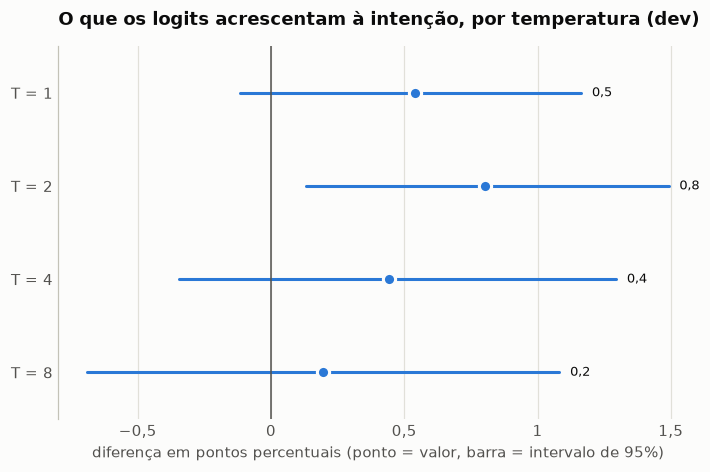

,intenção do B2,exact match do B2,intenção: B2 − B1 (intervalo de 95%),exact match: B2 − B1 (intervalo de 95%),intenção: a escolhida − esta (intervalo de 95%),intenção do B2 na rede do zero (Etapa 6),"época escolhida (sementes 0, 1 e 2)",escolhida
temperatura,,,,,,,,
1,"79,6","47,1","+0,5 (−0,1 a +1,2)","+0,3 (−0,4 a +1,0)","+0,3 (−0,3 a +0,9)","77,1","10, 10, 9",
2,"79,8","47,3","+0,8 (+0,1 a +1,5)","+0,6 (−0,2 a +1,3)",,"77,3","10, 9, 9",sim
4,"79,5","48,2","+0,4 (−0,3 a +1,3)","+1,4 (+0,5 a +2,3)","+0,4 (−0,2 a +1,0)","78,0","10, 9, 8",
8,"79,2","47,8","+0,2 (−0,7 a +1,1)","+1,1 (+0,1 a +2,0)","+0,6 (−0,2 a +1,5)","78,3","10, 10, 9",


In [15]:
b2_em_dev = {T: em_dev[etapa6.variante_do_b2(T)] for T in TEMPERATURAS}
T_escolhida, medias_por_T = etapa6.escolher_temperatura(ouro_dev, b2_em_dev)
assert T_escolhida == teste_da_etapa["temperatura_do_b2"], "A regra, refeita aqui, não aponta a temperatura para a qual o teste foi aberto."
B2 = etapa6.variante_do_b2(T_escolhida)
b2_menos_b1_dev = {T: qualidade.comparar_grupos(ouro_dev, em_dev["aluno_b1"], b2_em_dev[T]) for T in TEMPERATURAS}
contra_a_escolhida = {T: qualidade.comparar_grupos(ouro_dev, b2_em_dev[T], b2_em_dev[T_escolhida]) for T in TEMPERATURAS if T != T_escolhida}
so_as_previstas = {v for v in etapa10a.VARIANTES if (etapa10a.pasta_da_execucao(v, 0) / "previsoes_test.parquet").exists()} == {"teto", "piso", "aluno_a", "aluno_b1", B2}
temperaturas_do_zero = pd.read_csv(ENTREGAS / "06_destilacao" / "temperaturas.csv", index_col=0)   # a mesma grade, na rede do zero (Etapa 6)

fig, ax = visual.pontos_com_intervalo(
    {"Aluno B2 − aluno B1, em intenção": {f"T = {T}": trio(b2_menos_b1_dev[T].loc["intent_acc"], "diferenca") for T in TEMPERATURAS}},
    "O que os logits acrescentam à intenção, por temperatura (dev)", "diferença em pontos percentuais (ponto = valor, barra = intervalo de 95%)",
)
ax.axvline(0, color=visual.TINTA_SECUNDARIA, linewidth=1)
visual.salvar(fig, PASTA, "temperaturas")
plt.show()

pd.DataFrame({
    T: {
        "intenção do B2": pts(medias_por_T.loc[T, "intent_acc"]),
        "exact match do B2": pts(medias_por_T.loc[T, "exact_match"]),
        "intenção: B2 − B1 (intervalo de 95%)": com_intervalo(b2_menos_b1_dev[T].loc["intent_acc"]),
        "exact match: B2 − B1 (intervalo de 95%)": com_intervalo(b2_menos_b1_dev[T].loc["exact_match"]),
        "intenção: a escolhida − esta (intervalo de 95%)": "" if T == T_escolhida else com_intervalo(contra_a_escolhida[T].loc["intent_acc"]),
        "intenção do B2 na rede do zero (Etapa 6)": pts(temperaturas_do_zero.loc[T, "intent_acc"]),
        "época escolhida (sementes 0, 1 e 2)": epocas(etapa6.variante_do_b2(T)),
        "escolhida": "sim" if T == T_escolhida else "",
    }
    for T in TEMPERATURAS
}).T.rename_axis("temperatura")

In [16]:
melhor_que = [T for T, t in contra_a_escolhida.items() if t.loc["intent_acc", "ic_min"] > 0]
T_do_zero = do_zero["temperatura_do_b2"]
display(Markdown(f"""
**Leitura.**

- **Temperatura escolhida: T = {T_escolhida}** ({pts(medias_por_T.loc[T_escolhida, 'intent_acc'])}% de intenção em `dev`). No caminho do zero a escolhida foi T = {T_do_zero}.
- **As diferenças entre as temperaturas se distinguem?** A escolhida contra cada uma das outras, em intenção: {"; ".join(f"T = {T}: {com_intervalo(tab.loc['intent_acc'])}" for T, tab in contra_a_escolhida.items())}. A escolhida {"só é distinguivelmente melhor que T = " + ", ".join(map(str, melhor_que)) if melhor_que else "não é distinguivelmente melhor que nenhuma das outras"}; {"das demais ela não se separa, e outra amostra de `dev` poderia escolher diferente" if len(melhor_que) < len(contra_a_escolhida) else "ela se separa de todas"}.
- **Aqui a temperatura pesa menos que na rede do zero.** Entre a melhor e a pior temperatura há {num(100 * (medias_por_T["intent_acc"].max() - medias_por_T["intent_acc"].min()))} ponto de intenção com o XLM-R; na rede do zero havia {num(100 * (temperaturas_do_zero["intent_acc"].max() - temperaturas_do_zero["intent_acc"].min()))}, e a intenção subia com a temperatura até T = {T_do_zero}.
- {"A temperatura escolhida é a maior da grade: daqui não dá para saber se uma ainda maior seria melhor. A grade foi fixada antes de medir e não foi ampliada." if T_escolhida == max(TEMPERATURAS) else "A temperatura escolhida fica dentro da grade."}
- O teste só foi aberto para o teto, o piso, o aluno A, o B1 e o B2 em T = {T_escolhida}: {"confere" if so_as_previstas else "NÃO confere"}.
"""))


**Leitura.**

- **Temperatura escolhida: T = 2** (79,8% de intenção em `dev`). No caminho do zero a escolhida foi T = 8.
- **As diferenças entre as temperaturas se distinguem?** A escolhida contra cada uma das outras, em intenção: T = 1: +0,3 (−0,3 a +0,9); T = 4: +0,4 (−0,2 a +1,0); T = 8: +0,6 (−0,2 a +1,5). A escolhida não é distinguivelmente melhor que nenhuma das outras; das demais ela não se separa, e outra amostra de `dev` poderia escolher diferente.
- **Aqui a temperatura pesa menos que na rede do zero.** Entre a melhor e a pior temperatura há 0,6 ponto de intenção com o XLM-R; na rede do zero havia 1,2, e a intenção subia com a temperatura até T = 8.
- A temperatura escolhida fica dentro da grade.
- O teste só foi aberto para o teto, o piso, o aluno A, o B1 e o B2 em T = 2: confere.


## 8. Os sistemas no teste

Cinco sistemas com o XLM-R, os mesmos cinco da rede do zero e os dois professores.

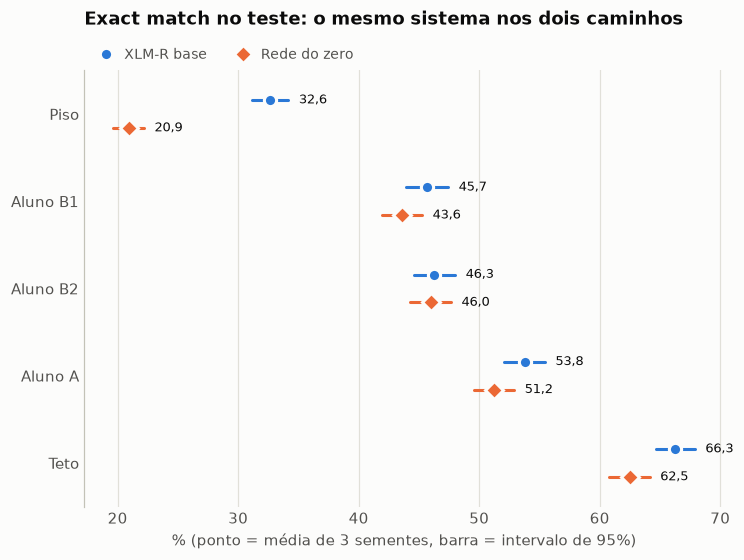

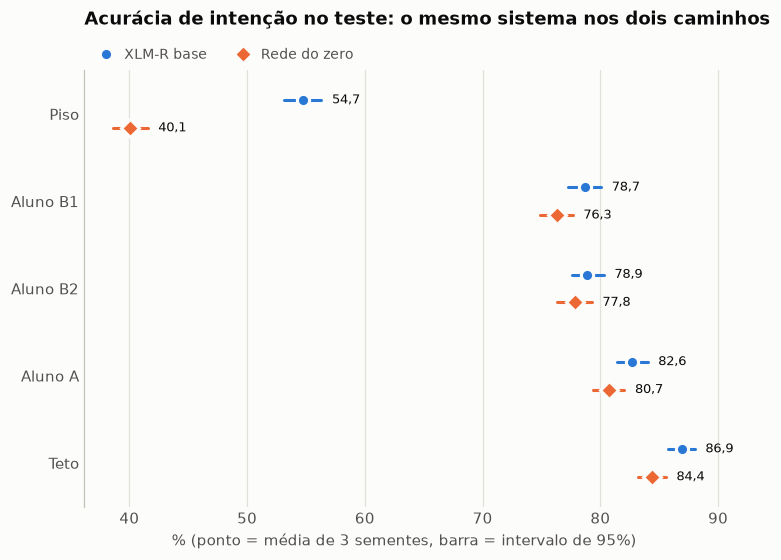

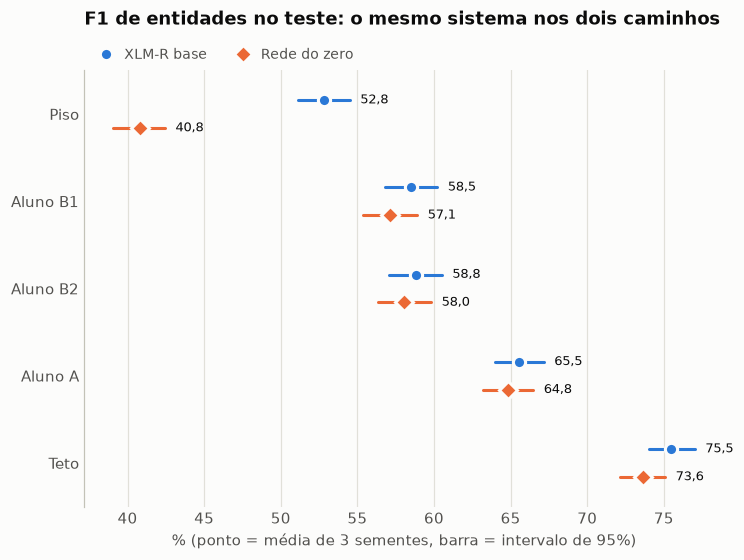

Teste, em % (intervalo de 95%). Sistemas treinados: média de 3 sementes.


,Acurácia de intenção,Macro-F1 de intenção,F1 de entidades,Exact match
XLM-R · Piso (299 rótulos humanos),"54,7 (53,1 a 56,3)","53,6 (51,7 a 55,7)","52,8 (51,1 a 54,5)","32,6 (31,1 a 34,2)"
Rede do zero · Piso (299 rótulos humanos),"40,1 (38,6 a 41,5)","39,3 (37,5 a 41,1)","40,8 (39,1 a 42,4)","20,9 (19,6 a 22,2)"
Qwen3-8B (professor aberto),"77,6 (76,1 a 79,1)","76,6 (74,7 a 79,2)","55,7 (53,9 a 57,4)","43,2 (41,5 a 45,0)"
XLM-R · Aluno B1 (rótulos do Qwen3-8B),"78,7 (77,2 a 80,1)","76,4 (74,4 a 78,9)","58,5 (56,8 a 60,2)","45,7 (44,0 a 47,4)"
Rede do zero · Aluno B1 (rótulos do Qwen3-8B),"76,3 (74,9 a 77,7)","74,5 (72,6 a 77,0)","57,1 (55,4 a 58,9)","43,6 (41,9 a 45,2)"
XLM-R · Aluno B2 (logits do Qwen3-8B),"78,9 (77,5 a 80,3)","76,9 (74,9 a 79,4)","58,8 (57,1 a 60,5)","46,3 (44,6 a 48,0)"
Rede do zero · Aluno B2 (logits do Qwen3-8B),"77,8 (76,3 a 79,3)","76,5 (74,6 a 78,7)","58,0 (56,3 a 59,8)","46,0 (44,2 a 47,6)"
Claude Haiku 5.5 (professor fechado),"83,5 (82,1 a 84,7)","82,1 (80,3 a 84,7)","66,1 (64,5 a 67,7)","54,0 (52,3 a 55,7)"
XLM-R · Aluno A (rótulos do Claude Haiku 5.5),"82,6 (81,4 a 84,0)","79,9 (78,0 a 82,5)","65,5 (64,0 a 67,2)","53,8 (52,1 a 55,4)"
Rede do zero · Aluno A (rótulos do Claude Haiku 5.5),"80,7 (79,4 a 82,0)","78,3 (76,4 a 80,7)","64,8 (63,2 a 66,5)","51,2 (49,6 a 52,9)"


In [17]:
NOME = {
    "teto": f"Teto ({n(len(treino))} rótulos humanos)", "piso": f"Piso ({n(execucoes['piso'][0]['meta']['exemplos_de_treino'])} rótulos humanos)",
    "A": f"Aluno A (rótulos do {FECHADO})", "B1": f"Aluno B1 (rótulos do {ABERTO})", "B2": f"Aluno B2 (logits do {ABERTO})",
    "fechado": f"{FECHADO} (professor fechado)", "aberto": f"{ABERTO} (professor aberto)",
}
CURTO = {"teto": "Teto", "piso": "Piso", "A": "Aluno A", "B1": "Aluno B1", "B2": "Aluno B2", "fechado": FECHADO, "aberto": ABERTO}
VARIANTE_DE = {"teto": "teto", "piso": "piso", "A": "aluno_a", "B1": "aluno_b1", "B2": B2}
CINCO = ("piso", "B1", "B2", "A", "teto")

# cada sistema é um grupo de respostas: 3 sementes para os treinados, uma execução para cada LLM
sistemas = {p: {**etapa10a.grupos_do_encoder(p, T_escolhida), **etapa10a.grupos_do_caminho_do_zero(p), **etapa10a.grupos_dos_professores(p)} for p in ("dev", "test")}
medidas = {p: {chave: qualidade.intervalo_do_grupo(gabarito[p], grupo) for chave, grupo in sistemas[p].items()} for p in ("dev", "test")}

for metrica, arquivo in (("exact_match", "os_dois_caminhos_exact_match"), ("intent_acc", "os_dois_caminhos_intencao"), ("slot_f1", "os_dois_caminhos_entidades")):
    fig, ax = visual.pontos_com_intervalo(
        {
            "XLM-R base": {CURTO[chave]: trio(medidas["test"][chave].loc[metrica]) for chave in CINCO},
            "Rede do zero": {CURTO[chave]: trio(medidas["test"][f"zero:{chave}"].loc[metrica]) for chave in CINCO},
        },
        f"{qualidade.NOMES[metrica]} no teste: o mesmo sistema nos dois caminhos", "% (ponto = média de 3 sementes, barra = intervalo de 95%)",
    )
    visual.salvar(fig, PASTA, arquivo)
    plt.show()

ORDEM = ["piso", "zero:piso", "aberto", "B1", "zero:B1", "B2", "zero:B2", "fechado", "A", "zero:A", "teto", "zero:teto"]
rotulo = lambda chave: f"Rede do zero · {NOME[chave[5:]]}" if chave.startswith("zero:") else NOME[chave] if chave in ("fechado", "aberto") else f"XLM-R · {NOME[chave]}"
print("Teste, em % (intervalo de 95%). Sistemas treinados: média de 3 sementes.")
pd.DataFrame({rotulo(chave): {qualidade.NOMES[m]: valor_com_intervalo(medidas["test"][chave].loc[m]) for m in qualidade.METRICAS} for chave in ORDEM}).T

In [18]:
desvios = pd.DataFrame({CURTO[chave]: medidas["test"][chave]["desvio_sementes"] for chave in CINCO}).loc[list(TRES)].rename(index=qualidade.NOMES)
print("XLM-R: desvio-padrão entre as 3 sementes, no teste (pontos percentuais)")
desvios.map(pts)

XLM-R: desvio-padrão entre as 3 sementes, no teste (pontos percentuais)


,Piso,Aluno B1,Aluno B2,Aluno A,Teto
Acurácia de intenção,"1,5","0,3","0,4","0,7","0,3"
F1 de entidades,"1,1","0,0","0,1","0,2","0,5"
Exact match,"1,1","0,4","0,7","0,6","0,4"


## 9. As comparações

A lista fechada da seção 2, no teste. Cada diferença é B − A, pareada: os mesmos sorteios do conjunto de teste para os dois lados.

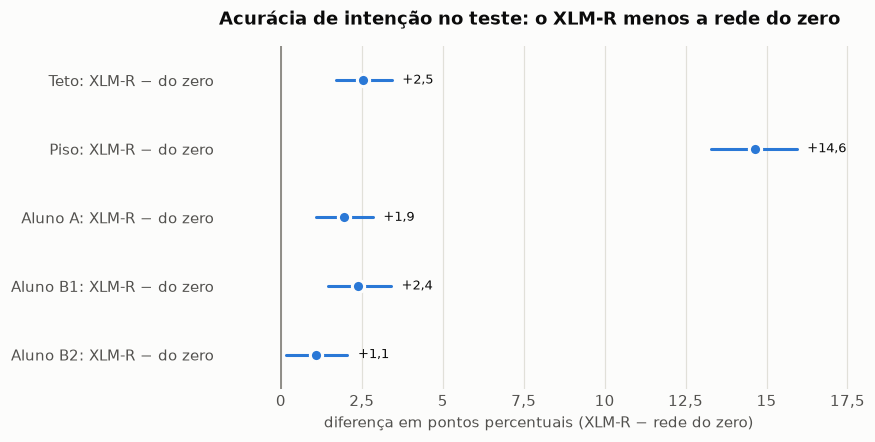

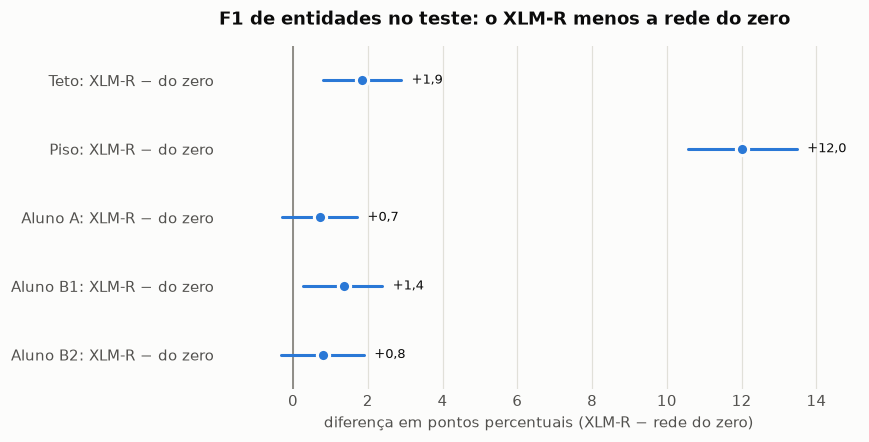

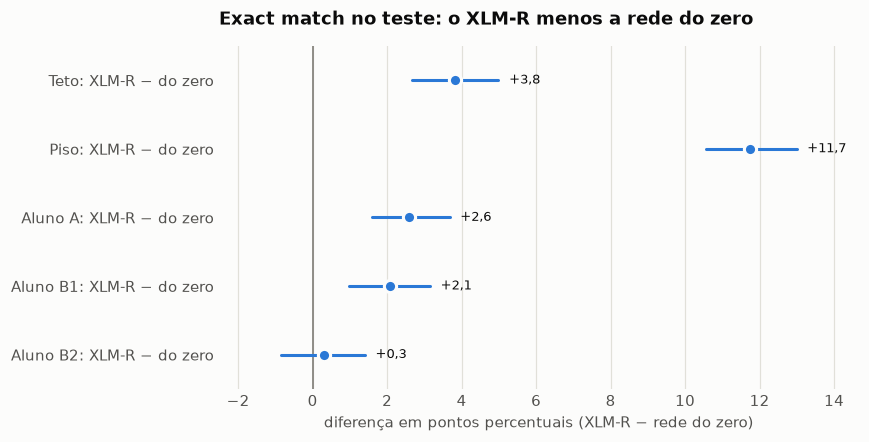

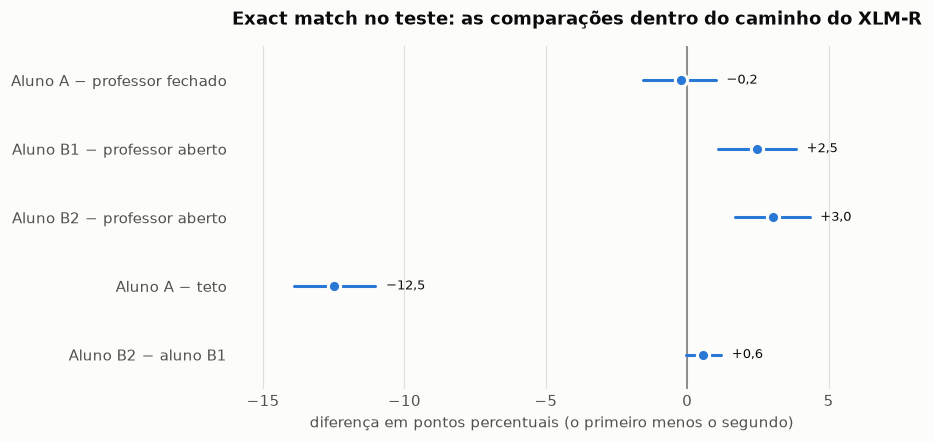

Teste: diferença em pontos percentuais (intervalo de 95%)


,Acurácia de intenção,Macro-F1 de intenção,F1 de entidades,Exact match
Teto: XLM-R − do zero,"+2,5 (+1,7 a +3,4)","+0,3 (−1,4 a +2,1)","+1,9 (+0,8 a +2,9)","+3,8 (+2,7 a +5,0)"
Piso: XLM-R − do zero,"+14,6 (+13,3 a +15,9)","+14,3 (+13,0 a +15,9)","+12,0 (+10,6 a +13,5)","+11,7 (+10,6 a +13,0)"
Aluno A: XLM-R − do zero,"+1,9 (+1,1 a +2,8)","+1,6 (+0,0 a +3,3)","+0,7 (−0,3 a +1,7)","+2,6 (+1,6 a +3,7)"
Aluno B1: XLM-R − do zero,"+2,4 (+1,5 a +3,4)","+1,9 (+0,4 a +3,4)","+1,4 (+0,3 a +2,4)","+2,1 (+1,0 a +3,1)"
Aluno B2: XLM-R − do zero,"+1,1 (+0,2 a +2,1)","+0,3 (−1,0 a +1,8)","+0,8 (−0,3 a +1,9)","+0,3 (−0,9 a +1,4)"
Aluno A − professor fechado,"−0,8 (−1,8 a +0,2)","−2,2 (−4,1 a −0,5)","−0,5 (−1,7 a +0,7)","−0,2 (−1,6 a +1,0)"
Aluno B1 − professor aberto,"+1,1 (−0,0 a +2,2)","−0,2 (−2,0 a +1,5)","+2,8 (+1,5 a +4,2)","+2,5 (+1,1 a +3,8)"
Aluno B2 − professor aberto,"+1,3 (+0,2 a +2,4)","+0,3 (−1,5 a +1,9)","+3,1 (+1,9 a +4,5)","+3,0 (+1,7 a +4,3)"
Aluno A − teto,"−4,3 (−5,3 a −3,3)","−3,2 (−4,8 a −1,8)","−10,0 (−11,3 a −8,6)","−12,5 (−13,9 a −11,0)"
Aluno B2 − aluno B1,"+0,2 (−0,3 a +0,8)","+0,5 (−0,5 a +1,4)","+0,3 (−0,2 a +0,9)","+0,6 (−0,0 a +1,2)"


In [19]:
contra = {p: etapa10a.comparar_tudo(gabarito[p], sistemas[p]) for p in ("dev", "test")}
c = {nome: tabela.set_index("metrica") for nome, tabela in contra["test"].groupby("comparacao", sort=False)}
ENTRE_CAMINHOS = [nome for nome, a, _, _ in etapa10a.COMPARACOES if a.startswith("zero:")]
DENTRO_DO_CAMINHO = [nome for nome, a, _, _ in etapa10a.COMPARACOES if not a.startswith("zero:")]

for metrica in TRES:
    fig, ax = visual.diferencas_com_intervalo(
        {nome: trio(c[nome].loc[metrica], "diferenca") for nome in ENTRE_CAMINHOS},
        f"{qualidade.NOMES[metrica]} no teste: o XLM-R menos a rede do zero", "diferença em pontos percentuais (XLM-R − rede do zero)",
    )
    visual.salvar(fig, PASTA, f"entre_caminhos_{metrica}")
    plt.show()
fig, ax = visual.diferencas_com_intervalo(
    {nome: trio(c[nome].loc["exact_match"], "diferenca") for nome in DENTRO_DO_CAMINHO},
    "Exact match no teste: as comparações dentro do caminho do XLM-R", "diferença em pontos percentuais (o primeiro menos o segundo)",
)
visual.salvar(fig, PASTA, "dentro_do_caminho_exact_match")
plt.show()

print("Teste: diferença em pontos percentuais (intervalo de 95%)")
pd.DataFrame({qualidade.NOMES[m]: {nome: com_intervalo(tabela.loc[m]) for nome, tabela in c.items()} for m in qualidade.METRICAS})

**O valor dos logits nos dois caminhos.** Com o XLM-R, do B1 para o B2 só os logits mudam. Na rede do zero o B1 tinha suavização de rótulos, e a Etapa 6 treinou um controle sem ela para isolar os logits. As duas linhas da rede do zero abaixo já foram medidas na Etapa 6; são refeitas aqui, das respostas entregues, só para ficarem ao lado da linha do XLM-R.

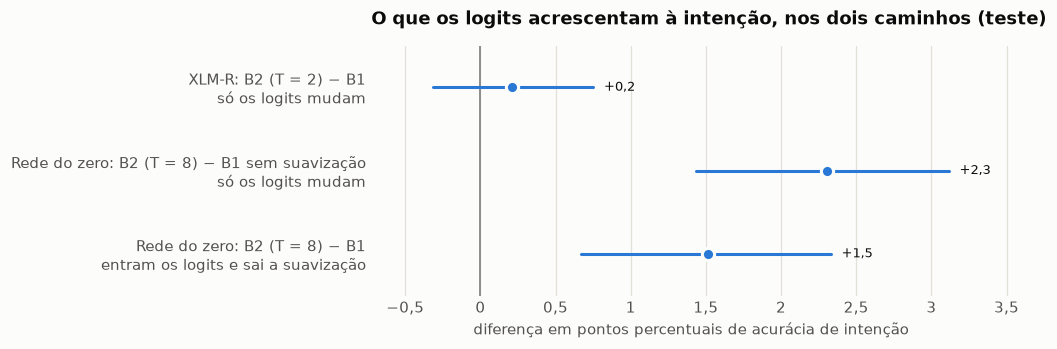

,Acurácia de intenção,F1 de entidades,Exact match
XLM-R: B2 (T = 2) − B1 · só os logits mudam,"+0,2 (−0,3 a +0,8)","+0,3 (−0,2 a +0,9)","+0,6 (−0,0 a +1,2)"
Rede do zero: B2 (T = 8) − B1 sem suavização · só os logits mudam,"+2,3 (+1,4 a +3,1)","+1,0 (+0,1 a +1,8)","+2,7 (+1,7 a +3,7)"
Rede do zero: B2 (T = 8) − B1 · entram os logits e sai a suavização,"+1,5 (+0,7 a +2,3)","+0,9 (+0,0 a +1,7)","+2,3 (+1,4 a +3,3)"


In [20]:
do_zero_no_teste = lambda v: [carregar_previsoes(ENTREGAS / "06_destilacao" / "previsoes" / f"{v}_semente_{s}_test.parquet")[1] for s in SEMENTES]
logits_do_zero = qualidade.comparar_grupos(ouro_teste, do_zero_no_teste("aluno_b1_sem_suavizacao"), sistemas["test"]["zero:B2"])
receitas_do_zero = qualidade.comparar_grupos(ouro_teste, sistemas["test"]["zero:B1"], sistemas["test"]["zero:B2"])
logits_lado_a_lado = {
    f"XLM-R: B2 (T = {T_escolhida}) − B1\nsó os logits mudam": c["Aluno B2 − aluno B1"],
    f"Rede do zero: B2 (T = {T_do_zero}) − B1 sem suavização\nsó os logits mudam": logits_do_zero,
    f"Rede do zero: B2 (T = {T_do_zero}) − B1\nentram os logits e sai a suavização": receitas_do_zero,
}
fig, ax = visual.diferencas_com_intervalo(
    {nome: trio(tabela.loc["intent_acc"], "diferenca") for nome, tabela in logits_lado_a_lado.items()},
    "O que os logits acrescentam à intenção, nos dois caminhos (teste)", "diferença em pontos percentuais de acurácia de intenção",
)
visual.salvar(fig, PASTA, "logits_nos_dois_caminhos")
plt.show()
pd.DataFrame({qualidade.NOMES[m]: {nome.replace("\n", " · "): com_intervalo(tabela.loc[m]) for nome, tabela in logits_lado_a_lado.items()} for m in TRES})

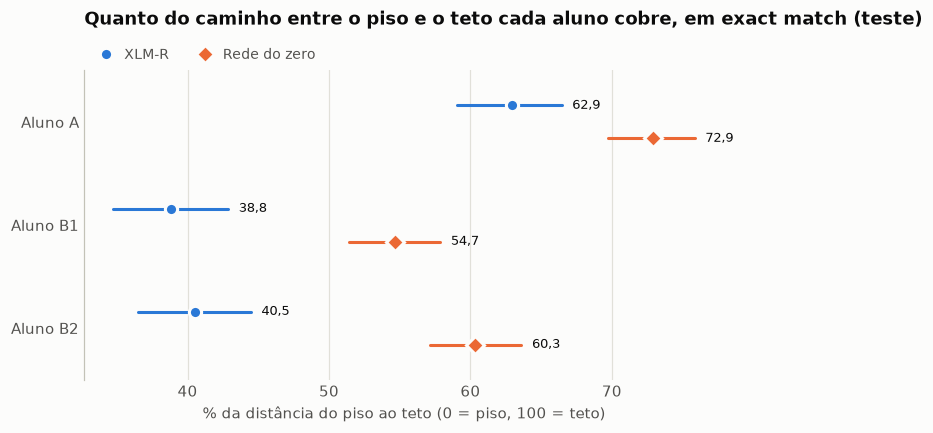

Acurácia de intenção F1 de entidades    Exact match
caminho      aluno                                                       
XLM-R        Aluno A         87% (84 a 90)   56% (51 a 61)  63% (59 a 66)
             Aluno B1        74% (71 a 78)   25% (19 a 31)  39% (35 a 43)
             Aluno B2        75% (72 a 78)   26% (21 a 32)  41% (36 a 44)
Rede do zero Aluno A         92% (90 a 94)   73% (70 a 77)  73% (70 a 76)
             Aluno B1        82% (79 a 84)   50% (46 a 54)  55% (51 a 58)
             Aluno B2        85% (83 a 88)   52% (48 a 56)  60% (57 a 64)

In [21]:
# A fração do caminho piso -> teto que cada aluno cobre, em cada caminho, com o piso e o teto do próprio caminho
fracoes = {}
for caminho, prefixo in (("XLM-R", ""), ("Rede do zero", "zero:")):
    for aluno in ("A", "B1", "B2"):
        s = sistemas["test"]
        fracoes[(caminho, CURTO[aluno])] = etapa10a.fracao_do_caminho(ouro_teste, s[f"{prefixo}piso"], s[f"{prefixo}teto"], s[f"{prefixo}{aluno}"])
fracao_com_intervalo = lambda linha: f"{pts(linha['valor'], 0)}% ({pts(linha['ic_min'], 0)} a {pts(linha['ic_max'], 0)})"
tabela_das_fracoes = pd.DataFrame({chave: {qualidade.NOMES[m]: fracao_com_intervalo(f.loc[m]) for m in TRES} for chave, f in fracoes.items()}).T.rename_axis(["caminho", "aluno"])

fig, ax = visual.pontos_com_intervalo(
    {caminho: {CURTO[aluno]: trio(fracoes[(caminho, CURTO[aluno])].loc["exact_match"]) for aluno in ("A", "B1", "B2")} for caminho in ("XLM-R", "Rede do zero")},
    "Quanto do caminho entre o piso e o teto cada aluno cobre, em exact match (teste)", "% da distância do piso ao teto (0 = piso, 100 = teto)",
)
visual.salvar(fig, PASTA, "fracao_do_caminho")
plt.show()
tabela_das_fracoes

In [22]:
em = lambda chave, m="exact_match": medidas["test"][chave].loc[m, "valor"]
fr = lambda caminho, aluno, m="exact_match": fracao_com_intervalo(fracoes[(caminho, CURTO[aluno])].loc[m])
logits = c["Aluno B2 − aluno B1"]
if logits.loc["intent_acc", "ic_min"] > 0:
    frase_dos_logits = "Os logits acrescentam: a intenção do B2 fica acima da do B1, com intervalo todo acima de zero."
elif logits.loc["intent_acc", "ic_max"] < 0:
    frase_dos_logits = "Os logits atrapalham: a intenção do B2 fica abaixo da do B1, com intervalo todo abaixo de zero."
else:
    frase_dos_logits = "Não dá para distinguir o aluno com logits do aluno com rótulos em intenção: o intervalo contém zero."

EM_FRASE = {"intent_acc": "acurácia de intenção", "slot_f1": "F1 de entidades", "exact_match": "exact match"}
minuscula = lambda texto: texto[0].lower() + texto[1:]   # "Aluno B1" -> "aluno B1", sem mexer na sigla
passam = [
    f"o {minuscula(CURTO[aluno])} em {EM_FRASE[m]} ({com_intervalo(c[nome].loc[m])})"
    for aluno, nome in (("A", "Aluno A − professor fechado"), ("B1", "Aluno B1 − professor aberto"), ("B2", "Aluno B2 − professor aberto"))
    for m in TRES if c[nome].loc[m, "ic_min"] > 0
]
frase_dos_professores = ("**Passam o próprio professor**, com intervalo todo acima de zero: " + "; ".join(passam) + "."
                         if passam else "Nenhum aluno passa o próprio professor de forma distinguível.")
ganha = [nome.split(":")[0] for nome in ENTRE_CAMINHOS if c[nome].loc["exact_match", "ic_min"] > 0]
nao_ganha = [nome.split(":")[0] for nome in ENTRE_CAMINHOS if not c[nome].loc["exact_match", "ic_min"] > 0]
frase_do_ganho = (f"Em exact match, o XLM-R fica distinguivelmente acima da rede do zero em {len(ganha)} dos {len(ENTRE_CAMINHOS)} sistemas"
                  + (f" ({', '.join(map(minuscula, ganha))})" if ganha else "")
                  + (f"; não se distingue em: {', '.join(map(minuscula, nao_ganha))}" if nao_ganha else "") + ". Em nenhum sistema e em nenhuma métrica ele fica distinguivelmente abaixo."
                  if not any(c[nome].loc[m, "ic_max"] < 0 for nome in ENTRE_CAMINHOS for m in TRES) else
                  f"Em exact match, o XLM-R fica distinguivelmente acima da rede do zero em {len(ganha)} dos {len(ENTRE_CAMINHOS)} sistemas; em pelo menos uma métrica de um sistema ele fica distinguivelmente abaixo (ver a tabela).")

display(Markdown(f"""
**Leitura, comparação por comparação (teste).**

1. **O mesmo sistema nos dois caminhos** (XLM-R − rede do zero).
   - Teto: o XLM-R fica {tres_posicoes(c['Teto: XLM-R − do zero'])}.
   - Piso: fica {tres_posicoes(c['Piso: XLM-R − do zero'])}.
   - Aluno A: fica {tres_posicoes(c['Aluno A: XLM-R − do zero'])}.
   - Aluno B1: fica {tres_posicoes(c['Aluno B1: XLM-R − do zero'])}.
   - Aluno B2 (XLM-R em T = {T_escolhida}, rede do zero em T = {T_do_zero}): fica {tres_posicoes(c['Aluno B2: XLM-R − do zero'])}.
   - {frase_do_ganho}
2. **Cada aluno contra o seu professor.**
   - O aluno A, contra o {FECHADO}, fica {tres_posicoes(c['Aluno A − professor fechado'])}.
   - O aluno B1, contra o {ABERTO}, fica {tres_posicoes(c['Aluno B1 − professor aberto'])}.
   - O aluno B2, contra o {ABERTO}, fica {tres_posicoes(c['Aluno B2 − professor aberto'])}.
   - {frase_dos_professores}
3. **O aluno A contra o teto** (o custo de não ter os {n(len(treino))} rótulos humanos): {tres_posicoes(c['Aluno A − teto'])}.
4. **O valor dos logits** (aluno B2 − aluno B1; só os logits mudam): {tres_posicoes(logits)}. {frase_dos_logits}
   - Na rede do zero (Etapa 6), também com só os logits mudando (B2 − B1 sem suavização), o B2 ficava {tres_posicoes(logits_do_zero)}.
5. **A fração do caminho, em exact match.** Com o XLM-R, o piso faz {pts(em('piso'))}% e o teto {pts(em('teto'))}%; o aluno A cobre {fr('XLM-R', 'A')} dessa distância, o B1 {fr('XLM-R', 'B1')} e o B2 {fr('XLM-R', 'B2')}. Na rede do zero, com o piso em {pts(em('zero:piso'))}% e o teto em {pts(em('zero:teto'))}%: {fr('Rede do zero', 'A')}, {fr('Rede do zero', 'B1')} e {fr('Rede do zero', 'B2')}. As frações dos dois caminhos não medem a mesma distância: cada caminho tem o seu piso e o seu teto.
"""))


**Leitura, comparação por comparação (teste).**

1. **O mesmo sistema nos dois caminhos** (XLM-R − rede do zero).
   - Teto: o XLM-R fica acima em intenção (+2,5 (+1,7 a +3,4)), acima em entidades (+1,9 (+0,8 a +2,9)) e acima em exact match (+3,8 (+2,7 a +5,0)).
   - Piso: fica acima em intenção (+14,6 (+13,3 a +15,9)), acima em entidades (+12,0 (+10,6 a +13,5)) e acima em exact match (+11,7 (+10,6 a +13,0)).
   - Aluno A: fica acima em intenção (+1,9 (+1,1 a +2,8)), sem diferença distinguível em entidades (+0,7 (−0,3 a +1,7)) e acima em exact match (+2,6 (+1,6 a +3,7)).
   - Aluno B1: fica acima em intenção (+2,4 (+1,5 a +3,4)), acima em entidades (+1,4 (+0,3 a +2,4)) e acima em exact match (+2,1 (+1,0 a +3,1)).
   - Aluno B2 (XLM-R em T = 2, rede do zero em T = 8): fica acima em intenção (+1,1 (+0,2 a +2,1)), sem diferença distinguível em entidades (+0,8 (−0,3 a +1,9)) e sem diferença distinguível em exact match (+0,3 (−0,9 a +1,4)).
   - Em exact match, o XLM-R fica distinguivelmente acima da rede do zero em 4 dos 5 sistemas (teto, piso, aluno A, aluno B1); não se distingue em: aluno B2. Em nenhum sistema e em nenhuma métrica ele fica distinguivelmente abaixo.
2. **Cada aluno contra o seu professor.**
   - O aluno A, contra o Claude Haiku 5.5, fica sem diferença distinguível em intenção (−0,8 (−1,8 a +0,2)), sem diferença distinguível em entidades (−0,5 (−1,7 a +0,7)) e sem diferença distinguível em exact match (−0,2 (−1,6 a +1,0)).
   - O aluno B1, contra o Qwen3-8B, fica sem diferença distinguível em intenção (+1,1 (−0,0 a +2,2)), acima em entidades (+2,8 (+1,5 a +4,2)) e acima em exact match (+2,5 (+1,1 a +3,8)).
   - O aluno B2, contra o Qwen3-8B, fica acima em intenção (+1,3 (+0,2 a +2,4)), acima em entidades (+3,1 (+1,9 a +4,5)) e acima em exact match (+3,0 (+1,7 a +4,3)).
   - **Passam o próprio professor**, com intervalo todo acima de zero: o aluno B1 em F1 de entidades (+2,8 (+1,5 a +4,2)); o aluno B1 em exact match (+2,5 (+1,1 a +3,8)); o aluno B2 em acurácia de intenção (+1,3 (+0,2 a +2,4)); o aluno B2 em F1 de entidades (+3,1 (+1,9 a +4,5)); o aluno B2 em exact match (+3,0 (+1,7 a +4,3)).
3. **O aluno A contra o teto** (o custo de não ter os 11.514 rótulos humanos): abaixo em intenção (−4,3 (−5,3 a −3,3)), abaixo em entidades (−10,0 (−11,3 a −8,6)) e abaixo em exact match (−12,5 (−13,9 a −11,0)).
4. **O valor dos logits** (aluno B2 − aluno B1; só os logits mudam): sem diferença distinguível em intenção (+0,2 (−0,3 a +0,8)), sem diferença distinguível em entidades (+0,3 (−0,2 a +0,9)) e sem diferença distinguível em exact match (+0,6 (−0,0 a +1,2)). Não dá para distinguir o aluno com logits do aluno com rótulos em intenção: o intervalo contém zero.
   - Na rede do zero (Etapa 6), também com só os logits mudando (B2 − B1 sem suavização), o B2 ficava acima em intenção (+2,3 (+1,4 a +3,1)), acima em entidades (+1,0 (+0,1 a +1,8)) e acima em exact match (+2,7 (+1,7 a +3,7)).
5. **A fração do caminho, em exact match.** Com o XLM-R, o piso faz 32,6% e o teto 66,3%; o aluno A cobre 63% (59 a 66) dessa distância, o B1 39% (35 a 43) e o B2 41% (36 a 44). Na rede do zero, com o piso em 20,9% e o teto em 62,5%: 73% (70 a 76), 55% (51 a 58) e 60% (57 a 64). As frações dos dois caminhos não medem a mesma distância: cada caminho tem o seu piso e o seu teto.


## 10. O custo

Protocolo da Etapa 2 (`avaliacao/eficiencia.py`): uma consulta por vez, 1 thread de CPU, do texto à resposta, 1.024 consultas medidas depois de 50 de aquecimento, com os pedidos de `dev`. São 5 rodadas, alternando o XLM-R (aluno A, semente 0) e o aluno A da rede do zero, em PyTorch. A medida roda fora do notebook (`uv run python -m especialista.experimentos.etapa10a latencia`), com a máquina quieta.

In [23]:
lat = etapa10a.carregar_latencia()
assert lat is not None, "Falta medir a latência, com a máquina quieta: uv run python -m especialista.experimentos.etapa10a latencia"
LIMITE_DE_OUTROS = 0.25   # núcleos de CPU que os outros processos podem ter ocupado durante a medida (o limite da Etapa 8)
zero_na_6 = float(resultados.carregar(ENTREGAS / "06_destilacao").query("particao == 'test' and variante == 'aluno_a'").iloc[0]["latencia_p50_ms"])
zero_agora = lat["resumo"]["do_zero"]["latencia_p50_ms"]
maquina_quieta = bool(lat["nucleos_de_outros"] <= LIMITE_DE_OUTROS and zero_agora <= 1.2 * zero_na_6)
tempos = {nome: lat["tempos"][nome].ravel() for nome in ("xlmr", "do_zero")}
p50_por_rodada = {nome: lat["p50_por_rodada_ms"][nome] for nome in tempos}

disco = meta_do_teto["bytes_em_disco"]
disco_do_zero = int(resultados.carregar(ENTREGAS / "06_destilacao").query("particao == 'test' and variante == 'aluno_a'").iloc[0]["bytes"])
custo = pd.DataFrame({
    "XLM-R base com cabeça conjunta": {
        "parâmetros": n(total), "dos quais, tabela de subtokens": n(partes["A. Tabela de subtokens"]), "tamanho em disco (MB)": n(round(disco / 1e6)),
        "latência p50 (ms), 1 núcleo de CPU": num(lat["resumo"]["xlmr"]["latencia_p50_ms"], 1), "latência p95 (ms)": num(lat["resumo"]["xlmr"]["latencia_p95_ms"], 1),
        "p50 de cada rodada (ms)": ", ".join(num(x, 1) for x in p50_por_rodada["xlmr"]),
    },
    "Rede do zero (aluno A), medida na mesma sessão": {
        "parâmetros": n(parametros_do_zero), "dos quais, tabela de subtokens": "—", "tamanho em disco (MB)": num(disco_do_zero / 1e6),
        "latência p50 (ms), 1 núcleo de CPU": num(zero_agora, 2), "latência p95 (ms)": num(lat["resumo"]["do_zero"]["latencia_p95_ms"], 2),
        "p50 de cada rodada (ms)": ", ".join(num(x, 2) for x in p50_por_rodada["do_zero"]),
    },
})
custo

,XLM-R base com cabeça conjunta,"Rede do zero (aluno A), medida na mesma sessão"
parâmetros,277.584.555,4.895.834
"dos quais, tabela de subtokens",192.001.536,—
tamanho em disco (MB),1.127,"19,9"
"latência p50 (ms), 1 núcleo de CPU","36,1","1,15"
latência p95 (ms),"48,0","1,72"
p50 de cada rodada (ms),"36,5, 36,0, 36,2, 35,7, 36,1","1,25, 1,13, 1,14, 1,10, 1,15"


In [24]:
vezes = lat["resumo"]["xlmr"]["latencia_p50_ms"] / zero_agora
display(Markdown(f"""
**Leitura.**

- **A máquina estava quieta?** {"Sim" if maquina_quieta else "**Não**"}. Durante a medida, os outros processos ocuparam {num(lat['nucleos_de_outros'], 2)} núcleo de CPU (o limite é {num(LIMITE_DE_OUTROS, 2)}). O aluno A da rede do zero deu {num(zero_agora, 2)} ms nesta sessão e {num(zero_na_6, 2)} ms na Etapa 6.{"" if maquina_quieta else " **As latências acima estão infladas e não valem como resultado.**"}
- **Latência:** {num(lat['resumo']['xlmr']['latencia_p50_ms'], 1)} ms no XLM-R, {num(vezes, 0)} vezes os {num(zero_agora, 2)} ms da rede do zero.
- **Tamanho:** {n(round(disco / 1e6))} MB em disco, {num(disco / disco_do_zero, 0)} vezes os {num(disco_do_zero / 1e6)} MB da rede do zero. Todas as variantes desta etapa têm a mesma rede: o custo é o mesmo para o teto, o piso e os alunos.
- Estes são os números de partida da Etapa 10b. Ainda não houve poda nem quantização, e o modelo está em PyTorch, em 32 bits.
"""))


**Leitura.**

- **A máquina estava quieta?** Sim. Durante a medida, os outros processos ocuparam 0,05 núcleo de CPU (o limite é 0,25). O aluno A da rede do zero deu 1,15 ms nesta sessão e 1,14 ms na Etapa 6.
- **Latência:** 36,1 ms no XLM-R, 31 vezes os 1,15 ms da rede do zero.
- **Tamanho:** 1.127 MB em disco, 57 vezes os 19,9 MB da rede do zero. Todas as variantes desta etapa têm a mesma rede: o custo é o mesmo para o teto, o piso e os alunos.
- Estes são os números de partida da Etapa 10b. Ainda não houve poda nem quantização, e o modelo está em PyTorch, em 32 bits.


## 11. O que segue para a compressão

A regra da seção 2, item 12, em `dev`, com os rótulos humanos.

In [25]:
segue = etapa10a.quem_segue(ouro_dev, {"A": em_dev["aluno_a"], "B1": em_dev["aluno_b1"], "B2": em_dev[B2]})
b2_b1 = segue["b2_menos_b1"]
display(Markdown(f"""
- **Seguem para a Etapa 10b: {" e ".join(NOME[a] for a in segue["seguem"])}**, os mesmos do caminho do zero ({" e ".join(do_zero["seguem"])}).
- Principal: {CURTO[segue["principal"]]} ({", ".join(f"{CURTO[a]}: {pts(v)}% de exact match em dev" for a, v in segue["exact_match_em_dev"].items())}). No caminho do zero o principal foi o aluno {do_zero["principal"]}.
- Conferência pela regra da Etapa 6, em `dev`: B2 − B1 dá {com_intervalo(b2_b1.loc["intent_acc"])} em intenção e {com_intervalo(b2_b1.loc["exact_match"])} em exact match. {"O B2 passaria na regra da Etapa 6." if segue["b2_passa_na_regra_da_etapa_6"] else "**O B2 não passaria na regra da Etapa 6**: pela regra de lá seguiria o B1. Aqui o B2 segue mesmo assim, para que a Etapa 10c compare os mesmos alunos nos dois caminhos."}
"""))


- **Seguem para a Etapa 10b: Aluno A (rótulos do Claude Haiku 5.5) e Aluno B2 (logits do Qwen3-8B)**, os mesmos do caminho do zero (A e B2).
- Principal: Aluno A (Aluno A: 54,4% de exact match em dev, Aluno B2: 47,3% de exact match em dev). No caminho do zero o principal foi o aluno A.
- Conferência pela regra da Etapa 6, em `dev`: B2 − B1 dá +0,8 (+0,1 a +1,5) em intenção e +0,6 (−0,2 a +1,3) em exact match. O B2 passaria na regra da Etapa 6.


## 12. Entrega

Vão para a entrega os modelos que a Etapa 10b lê (o teto e os dois alunos que seguem, 3 sementes cada), as respostas de todos os treinos, cada comparação, o custo e a decisão.

In [26]:
# 1. Modelos (o teto e os que seguem), respostas e históricos
ENTREGUES = ("teto", *segue["seguem"])


def copiar_modelo(origem, destino):
    """Copia a pasta do modelo. No mesmo disco, o arquivo de pesos vira um segundo nome do mesmo arquivo, sem ocupar o dobro."""
    if destino.exists():
        shutil.rmtree(destino)
    try:
        shutil.copytree(origem, destino, copy_function=os.link)
    except OSError:
        if destino.exists():
            shutil.rmtree(destino)
        shutil.copytree(origem, destino)


for chave in ENTREGUES:
    for semente, e in zip(SEMENTES, execucoes[VARIANTE_DE[chave]]):
        copiar_modelo(e["pasta"] / "modelo", PASTA / "modelos" / VARIANTE_DE[chave] / f"semente_{semente}")
(PASTA / "historicos").mkdir(exist_ok=True)
for v, es in {**{v: [e] for v, e in busca.items()}, **execucoes}.items():
    for semente, e in zip(SEMENTES, es):
        salvar_previsoes(PASTA / "previsoes" / f"{v}_semente_{semente}_dev.parquet", dev["id"], e["previsoes_dev"])
        e["historico"].to_csv(PASTA / "historicos" / f"{v}_semente_{semente}.csv", index=False)
for chave, v in VARIANTE_DE.items():
    for semente, previsoes in zip(SEMENTES, sistemas["test"][chave]):
        salvar_previsoes(PASTA / "previsoes" / f"{v}_semente_{semente}_test.parquet", teste["id"], previsoes)

# 2. Os modelos da entrega, relidos do disco na CPU, reproduzem as respostas do teste? (semente 0 de cada um)
#    As respostas gravadas saíram na placa de vídeo; na CPU o arredondamento é outro, e um empate quase exato pode virar.
TOLERANCIA_DE_ARREDONDAMENTO = 0.005
iguais = {}
for chave in ENTREGUES:
    relido = SistemaEncoder.carregar(PASTA / "modelos" / VARIANTE_DE[chave] / "semente_0", "cpu").prever(list(teste["utt"]))
    iguais[chave] = float(np.mean([a == b for a, b in zip(relido, sistemas["test"][chave][0])]))
recarrega_ok = all(parte >= 1 - TOLERANCIA_DE_ARREDONDAMENTO for parte in iguais.values())

# 3. A tabela de resultados: os cinco sistemas em dev e teste; a busca e as outras temperaturas do B2 só em dev
linhas_resultado = []
for chave, v in VARIANTE_DE.items():
    for particao in ("dev", "test"):
        linhas_resultado.append(resultados.registrar_grupo(
            f"XLM-R base, {NOME[chave][0].lower() + NOME[chave][1:]}, média de {len(SEMENTES)} sementes", particao, gabarito[particao], sistemas[particao][chave],
            tempos_ms=tempos["xlmr"] if chave == "A" else None, parametros=total, bytes_em_disco=disco, threads=1, variante=v,
            maquina_quieta=maquina_quieta if chave == "A" else None,
        ))
for T in TEMPERATURAS:
    if T != T_escolhida:
        v = etapa6.variante_do_b2(T)
        linhas_resultado.append(resultados.registrar_grupo(
            f"XLM-R base, aluno B2 (logits do {ABERTO}, T = {T}), média de {len(SEMENTES)} sementes", "dev", ouro_dev, em_dev[v], parametros=total, variante=v,
        ))
for v, e in busca.items():
    linhas_resultado.append(resultados.registrar(f"XLM-R base, {e['meta']['nome'][0].lower() + e['meta']['nome'][1:]}", "dev", ouro_dev, e["previsoes_dev"], parametros=total, variante=v))
resultados.salvar(linhas_resultado, PASTA)

# 4. As comparações, a busca, a grade de temperaturas, a fração do caminho e o custo
pd.concat({p: contra[p] for p in ("dev", "test")}, names=["particao"]).reset_index(level=0).to_csv(PASTA / "comparacoes.csv", index=False)
tabela_da_busca.assign(melhor_epoca=[busca[v]["meta"]["melhor_epoca"] for v in tabela_da_busca.index], escolhida=tabela_da_busca.index == vencedora).to_csv(PASTA / "busca.csv")
medias_por_T.assign(
    b2_menos_b1_intencao=pd.Series({T: b2_menos_b1_dev[T].loc["intent_acc", "diferenca"] for T in TEMPERATURAS}),
    b2_menos_b1_ic_min=pd.Series({T: b2_menos_b1_dev[T].loc["intent_acc", "ic_min"] for T in TEMPERATURAS}),
    b2_menos_b1_ic_max=pd.Series({T: b2_menos_b1_dev[T].loc["intent_acc", "ic_max"] for T in TEMPERATURAS}),
    escolhida=[T == T_escolhida for T in medias_por_T.index],
).to_csv(PASTA / "temperaturas.csv")
pd.concat({f"{caminho} · {aluno}": f.loc[list(qualidade.METRICAS)] for (caminho, aluno), f in fracoes.items()}, names=["sistema", "metrica"]).to_csv(PASTA / "fracao_do_caminho.csv")
tabela_do_portao.to_csv(PASTA / "teto_contra_o_publicado.csv")
mista_menos_32.loc[list(qualidade.METRICAS)].rename(columns={"a": "todo_em_32_bits", "b": "precisao_mista"}).to_csv(PASTA / "controle_de_32_bits.csv")
(PASTA / "custo.json").write_text(json.dumps({
    "parametros": total, "parametros_por_parte": partes, "linhas_da_tabela": linhas_da_tabela, "linhas_da_tabela_no_treino": usadas,
    "bytes_em_disco": disco, "latencia": {k: v for k, v in lat.items() if k != "tempos"}, "maquina_quieta": maquina_quieta,
    "treino": {"segundos_por_epoca": float(segundos_por_epoca), "pico_de_vram_gb": float(pico_de_vram), "horas_de_treino": float(horas_de_gpu)},
}, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")

# 5. A decisão: é este arquivo que a Etapa 10b lê
relativo = lambda caminho: str(caminho.relative_to(RAIZ))
pastas_por_semente = lambda raiz: {str(semente): relativo(raiz / f"semente_{semente}") for semente in SEMENTES}
decisao = {
    "como_ler": ("`seguem` traz as siglas dos alunos que a Etapa 10b comprime, e `principal`, o que ela comprime primeiro. Em `alunos` e em "
                 "`referencias.teto`, toda pasta de `pastas_por_semente` é lida por especialista.modelos.encoder.SistemaEncoder.carregar. "
                 "`sinal` diz de onde vêm os rótulos do treino e da parada de cada aluno: é com ele que o reajuste depois da poda tem de continuar."),
    "etapa": "10a_encoder",
    "gerado_em": date.today().isoformat(),
    "encoder": {"modelo_id": Config().modelo_id, "revisao": Config().revisao},
    "receita": receita_do_teto,
    "regra_da_receita": etapa10a.REGRA_DA_RECEITA,
    "teto_perto_do_publicado": passou,
    "regra_do_teto": etapa10a.REGRA_DO_PORTAO,
    "temperatura_do_b2": int(T_escolhida),
    "regra_da_temperatura": teste_da_etapa["regra_da_temperatura"],
    "seguem": segue["seguem"],
    "principal": segue["principal"],
    "regra_do_que_segue": etapa10a.REGRA_DO_QUE_SEGUE,
    "b2_passa_na_regra_da_etapa_6": segue["b2_passa_na_regra_da_etapa_6"],
    "alunos": {
        chave: {
            "nome": NOME[chave],
            "segue": chave in segue["seguem"],
            "variante": VARIANTE_DE[chave],
            "modelos": relativo(PASTA / "modelos" / VARIANTE_DE[chave]) if chave in ENTREGUES else None,
            "pastas_por_semente": pastas_por_semente(PASTA / "modelos" / VARIANTE_DE[chave]) if chave in ENTREGUES else None,
            "sementes": list(SEMENTES),
            "config": execucoes[VARIANTE_DE[chave]][0]["meta"]["config"],
            "receita": execucoes[VARIANTE_DE[chave]][0]["meta"]["receita"],
            "sinal": execucoes[VARIANTE_DE[chave]][0]["meta"]["origem"],
            "exact_match_em_dev": float(medidas["dev"][chave].loc["exact_match", "valor"]),
        }
        for chave in ("A", "B1", "B2")
    },
    "referencias": {
        "teto": {"modelos": relativo(PASTA / "modelos" / "teto"), "pastas_por_semente": pastas_por_semente(PASTA / "modelos" / "teto"),
                 "config": meta_do_teto["config"], "receita": meta_do_teto["receita"], "sinal": meta_do_teto["origem"]},
        "caminho_do_zero": "entregas/06_destilacao/decisao.json",
    },
    "custo_de_partida": {
        "parametros": total, "parametros_por_parte": partes, "linhas_da_tabela_de_subtokens": linhas_da_tabela,
        "linhas_da_tabela_usadas_no_treino": usadas, "bytes_em_disco_por_modelo": disco,
        "latencia_p50_ms_cpu_1_thread": lat["resumo"]["xlmr"]["latencia_p50_ms"], "maquina_quieta": maquina_quieta,
    },
    "controle_de_32_bits": {"entra_em_decisao": False, "precisao_mista_menos_32_bits_em_dev": {
        m: {k: float(mista_menos_32.loc[m, k]) for k in ("diferenca", "ic_min", "ic_max")} for m in TRES}},
}
(PASTA / "decisao.json").write_text(json.dumps(decisao, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")

print("Modelos da entrega, relidos do disco na CPU: parte dos pedidos do teste com a mesma resposta gravada")
pd.Series({NOME[chave]: f"{pts(parte, 2)}%" for chave, parte in iguais.items()}, name="respostas iguais").to_frame()

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 4287.92it/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 4396.24it/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 4222.66it/s]

Modelos da entrega, relidos do disco na CPU: parte dos pedidos do teste com a mesma resposta gravada


,respostas iguais
Teto (11.514 rótulos humanos),"100,00%"
Aluno A (rótulos do Claude Haiku 5.5),"100,00%"
Aluno B2 (logits do Qwen3-8B),"100,00%"


### Critério de pronto

In [27]:
pronto = pd.Series({
    "A receita do teto saiu da busca em dev, pela regra escrita antes, e todos os outros treinos herdam essa receita":
        vencedora == decidido["vencedora"] and len(busca) == 6 and como_declarado and teto_0_e_a_busca,
    f"Cada sistema treinado tem 3 sementes ({len(execucoes)} variantes)": all(len(es) == len(SEMENTES) for es in execucoes.values()) and mesma_rede,
    "O teto ficou perto da linha publicada do MASSIVE, pela regra escrita antes": bool(passou),
    "Nenhum rótulo humano entrou no treino nem na parada dos alunos": bool(sem_humano),
    "A temperatura do B2 saiu de dev, pela regra da Etapa 6, e o teste só foi aberto para os sistemas previstos":
        T_escolhida in TEMPERATURAS and T_escolhida == teste_da_etapa["temperatura_do_b2"] and so_as_previstas,
    f"Cada comparação da lista fechada é pareada, com intervalo de 95%, no teste ({len(c)} comparações)":
        list(c) == [nome for nome, *_ in etapa10a.COMPARACOES] and all({"ic_min", "ic_max"} <= set(t.columns) for t in c.values()),
    "Os modelos entregues, relidos do disco na CPU, reproduzem as respostas do teste": bool(recarrega_ok),
    "O custo foi medido: parâmetros por parte, tamanho em disco e latência com a máquina quieta":
        sum(partes.values()) == total and disco > 0 and maquina_quieta,
}).map({True: "sim", False: "NÃO"}).rename("atendido").to_frame()
assert (pronto["atendido"] == "sim").all()
pronto

,atendido
"A receita do teto saiu da busca em dev, pela regra escrita antes, e todos os outros treinos herdam essa receita",sim
Cada sistema treinado tem 3 sementes (8 variantes),sim
"O teto ficou perto da linha publicada do MASSIVE, pela regra escrita antes",sim
Nenhum rótulo humano entrou no treino nem na parada dos alunos,sim
"A temperatura do B2 saiu de dev, pela regra da Etapa 6, e o teste só foi aberto para os sistemas previstos",sim
"Cada comparação da lista fechada é pareada, com intervalo de 95%, no teste (10 comparações)",sim
"Os modelos entregues, relidos do disco na CPU, reproduzem as respostas do teste",sim
"O custo foi medido: parâmetros por parte, tamanho em disco e latência com a máquina quieta",sim


## 13. Resposta

O resumo abaixo é gerado a partir dos números calculados neste notebook e gravado em `entregas/10a_encoder/RESUMO.md`.

In [28]:
t = medidas["test"]
tres_valores = lambda chave: f"{pts(t[chave].loc['intent_acc', 'valor'])} / {pts(t[chave].loc['slot_f1', 'valor'])} / {pts(t[chave].loc['exact_match', 'valor'])}"
tabela_teste = "\n".join(f"| {rotulo(chave)} | " + " | ".join(valor_com_intervalo(t[chave].loc[m]) for m in qualidade.METRICAS) + " |" for chave in ORDEM)
tabela_comparacoes = "\n".join(f"| {nome} | " + " | ".join(com_intervalo(tabela.loc[m]) for m in TRES) + " |" for nome, tabela in c.items())
tabela_busca = "\n".join(
    f"| {l['taxa']} | {l['épocas']} | {l['melhor época']} | {l['intenção']} | {l['entidades (F1)']} | {l['exact match']} | {l['vencedora − esta, em exact match']} | {l['escolhida']} |"
    for l in linhas_da_busca
)
tabela_publicado = "\n".join(
    f"| {qualidade.NOMES[m]} | {pts(l['teto'])} ({pts(l['ic_min'])} a {pts(l['ic_max'])}) | {pts(l['publicado'])} ± {pts(l['margem_publicada'])} | {dif(l['diferenca'])} | {'sim' if l['perto'] else 'NÃO'} |"
    for m, l in tabela_do_portao.iterrows()
)
tabela_temperaturas = "\n".join(
    f"| {T} | {pts(medias_por_T.loc[T, 'intent_acc'])} | {pts(medias_por_T.loc[T, 'exact_match'])} | {com_intervalo(b2_menos_b1_dev[T].loc['intent_acc'])} | "
    f"{'' if T == T_escolhida else com_intervalo(contra_a_escolhida[T].loc['intent_acc'])} | {pts(temperaturas_do_zero.loc[T, 'intent_acc'])} | {'sim' if T == T_escolhida else ''} |"
    for T in TEMPERATURAS
)
tabela_logits = "\n".join(f"| {nome.replace(chr(10), ' · ')} | " + " | ".join(com_intervalo(tabela.loc[m]) for m in TRES) + " |" for nome, tabela in logits_lado_a_lado.items())
tabela_pronto = "\n".join(f"| {criterio} | {atendido} |" for criterio, atendido in pronto["atendido"].items())
tabela_fracoes = "\n".join(
    f"| {caminho} | {aluno} | " + " | ".join(fracao_com_intervalo(f.loc[m]) for m in TRES) + " |" for (caminho, aluno), f in fracoes.items()
)
tabela_treinos = "\n".join(
    f"| {l['sistema']} | {l['rótulos do treino']} | {l['exemplos de treino']} | {l['passos de treino']} | {l['quem escolhe a época de parada']} | {l['época escolhida (sementes 0, 1 e 2)']} |"
    for l in linhas_dos_treinos
)
tabela_partes = "\n".join(f"| {parte} | {n(q)} | {pts(q / total)}% |" for parte, q in partes.items())

resposta = (
    f"Com os {n(len(treino))} rótulos humanos, o XLM-R base faz no teste {tres_valores('teto')} (intenção / F1 de entidades / exact match); a rede do zero fazia {tres_valores('zero:teto')}. "
    f"Contra o teto da rede do zero, o do XLM-R fica {tres_posicoes(c['Teto: XLM-R − do zero'])}. "
    f"Contra a linha publicada do XLM-R base no MASSIVE (86,7 / 73,3 / 64,6), ele {'fica perto' if passou else 'NÃO fica perto'}, pela regra escrita antes. "
    f"**No piso**, com só os 299 rótulos humanos, o XLM-R faz {tres_valores('piso')}, contra {tres_valores('zero:piso')} da rede do zero: fica {tres_posicoes(c['Piso: XLM-R − do zero'])}. "
    f"**Nos alunos**, contra o mesmo aluno da rede do zero: o aluno A ({tres_valores('A')}) fica {tres_posicoes(c['Aluno A: XLM-R − do zero'])}; "
    f"o B1 ({tres_valores('B1')}) fica {tres_posicoes(c['Aluno B1: XLM-R − do zero'])}; "
    f"o B2, em T = {T_escolhida} ({tres_valores('B2')}), fica {tres_posicoes(c['Aluno B2: XLM-R − do zero'])}. "
    f"Contra o seu professor, o aluno A fica {tres_posicoes(c['Aluno A − professor fechado'])}. {frase_dos_professores} "
    f"Contra o teto, fica {tres_posicoes(c['Aluno A − teto'])}; em exact match ele cobre {fr('XLM-R', 'A')} da distância entre o piso e o teto do XLM-R (na rede do zero, {fr('Rede do zero', 'A')}). "
    f"**Os logits** (B2 − B1, só os logits mudam): {tres_posicoes(logits)}. {frase_dos_logits} "
    f"**O custo:** {n(total)} parâmetros ({pts(partes['A. Tabela de subtokens'] / total)}% na tabela de subtokens), {n(round(disco / 1e6))} MB em disco "
    f"({num(disco / disco_do_zero, 0)} vezes o tamanho da rede do zero) e {num(lat['resumo']['xlmr']['latencia_p50_ms'], 1)} ms por pedido em 1 núcleo de CPU "
    f"({num(vezes, 0)} vezes a latência da rede do zero, que responde em {num(zero_agora, 2)} ms)."
)

resumo = f"""# Etapa 10a · Encoder pré-treinado, teto e alunos: resumo da entrega

**Pergunta.** Com um encoder pré-treinado no lugar da rede do zero, o que muda no teto e no que o aluno aprende de cada professor?

**Resposta.** {resposta}

Seguem para a compressão (Etapa 10b): **{" e ".join(NOME[a] for a in segue["seguem"])}**. O principal é o {CURTO[segue["principal"]]}.{"" if segue["b2_passa_na_regra_da_etapa_6"] else " O B2 não passaria na regra da Etapa 6 (B2 − B1 em dev); segue mesmo assim, para que os dois caminhos comprimam os mesmos alunos."}

## A rede

XLM-R base (`{Config().modelo_id}`) com duas cabeças lineares, no desenho do JointBERT (Chen et al., arXiv 1902.10909): intenção sobre o primeiro token, entidades sobre o primeiro subtoken de cada palavra, sem CRF.

| Parte | Parâmetros | Parte do modelo |
|---|---|---|
{tabela_partes}
| Total | {n(total)} | 100,0% |

- Dos {n(linhas_da_tabela)} subtokens da tabela, o treino usa {n(usadas)} ({pts(usadas / linhas_da_tabela)}%).

## A receita do teto (busca em dev, 1 semente por configuração)

| Taxa | Épocas | Melhor época | Intenção | Entidades (F1) | Exact match | Vencedora − esta, em exact match (intervalo de 95%) | Escolhida |
|---|---|---|---|---|---|---|---|
{tabela_busca}

![A busca](figuras/busca_da_receita.png)

- Regra: {etapa10a.REGRA_DA_RECEITA}.
- O resto da receita não entrou na busca: lote de {RECEITA.lote}, AdamW com decaimento de {num(RECEITA.decaimento, 2)}, taxa que sobe em {pts(RECEITA.aquecimento, 0)}% dos passos e desce em linha reta até zero, corte da norma do gradiente em {num(RECEITA.norma_maxima)}, parada pelo melhor exact match em `dev`, medido a cada época.

## O teto contra a linha publicada (teste)

| Métrica | Teto com o XLM-R (intervalo de 95%) | Publicado (± margem de 95%) | Diferença | Os intervalos se tocam, ou o teto está acima |
|---|---|---|---|---|
{tabela_publicado}

![O teto e o publicado](figuras/teto_contra_o_publicado.png)

- Regra: {etapa10a.REGRA_DO_PORTAO}.
- O modelo publicado (FitzGerald et al., arXiv 2204.08582) treinou com os 51 idiomas juntos; o deste projeto, só com pt-PT.

## Os treinos

Todos com a mesma rede e a receita do teto (taxa de {taxa(RECEITA.taxa)}, {RECEITA.epocas} épocas), 3 sementes. O que muda é de onde vêm os rótulos.

| Sistema | Rótulos do treino | Exemplos de treino | Passos de treino | Quem escolhe a época de parada | Época escolhida (sementes 0, 1 e 2) |
|---|---|---|---|---|---|
{tabela_treinos}

- **O piso tem o mesmo número de passos dos outros**, e não o mesmo número de épocas (Mosbach et al., arXiv 2006.04884: com poucos exemplos, o que decide o ajuste fino é o número de passos). Aqui cada treino do piso deu {n(piso_aqui['passos'])} passos, cerca de {n(piso_aqui['passadas'])} passadas pelos {exemplos_do_piso} exemplos. No caminho do zero o piso deu {n(piso_do_zero['passos'])} passos, cerca de {n(piso_do_zero['passadas'])} passadas, porque o balanceamento por intenção da receita de lá repete os exemplos até cada intenção aparecer 100 vezes por época. Lá cada intenção pesa igual; aqui cada exemplo pesa igual. A comparação piso × piso carrega essa diferença.
- **Controle da precisão mista** (o teto da semente 0 treinado todo em 32 bits; não entra em decisão): {frase_do_controle}. {"Nenhuma das três se distingue de zero." if not mista_distinguivel else "Distingue-se de zero em: " + ", ".join(mista_distinguivel) + "."} Os dois treinos dão a mesma resposta em {pts(iguais_ao_controle)}% dos pedidos de `dev`; duas sementes do teto concordam em {pts(iguais_entre_sementes)}%.

## No teste

Em % (intervalo de 95%). Sistemas treinados: média de 3 sementes.

| Sistema | Acurácia de intenção | Macro-F1 de intenção | F1 de entidades | Exact match |
|---|---|---|---|---|
{tabela_teste}

![Os dois caminhos](figuras/os_dois_caminhos_exact_match.png)

## As comparações (teste)

Diferença pareada, em pontos percentuais (intervalo de 95%). Uma diferença só vale quando o intervalo não contém zero. A lista foi fechada antes dos treinos.

| Comparação | Acurácia de intenção | F1 de entidades | Exact match |
|---|---|---|---|
{tabela_comparacoes}

![Entre os caminhos](figuras/entre_caminhos_exact_match.png)

![Dentro do caminho](figuras/dentro_do_caminho_exact_match.png)

- {frase_do_ganho}
- {frase_dos_professores}

### O valor dos logits nos dois caminhos (teste)

| Comparação | Acurácia de intenção | F1 de entidades | Exact match |
|---|---|---|---|
{tabela_logits}

![Logits nos dois caminhos](figuras/logits_nos_dois_caminhos.png)

- As duas linhas da rede do zero são da Etapa 6, refeitas das respostas entregues.

## A fração do caminho entre o piso e o teto (teste)

(aluno − piso) / (teto − piso), com intervalo de 95%. Cada caminho usa o seu piso e o seu teto.

| Caminho | Aluno | Acurácia de intenção | F1 de entidades | Exact match |
|---|---|---|---|---|
{tabela_fracoes}

![Fração do caminho](figuras/fracao_do_caminho.png)

## A temperatura do aluno B2 (dev)

| T | Intenção do B2 | Exact match do B2 | Intenção: B2 − B1 (intervalo de 95%) | Intenção: a escolhida − esta (intervalo de 95%) | Intenção do B2 na rede do zero (Etapa 6) | Escolhida |
|---|---|---|---|---|---|---|
{tabela_temperaturas}

![Temperaturas](figuras/temperaturas.png)

- Regra: a da Etapa 6 (maior acurácia de intenção em `dev`, com os rótulos humanos, na média de 3 sementes). No caminho do zero a escolhida foi T = {T_do_zero}.
- A escolhida {"só é distinguivelmente melhor que T = " + ", ".join(map(str, melhor_que)) if melhor_que else "não é distinguivelmente melhor que nenhuma das outras"}: entre a melhor e a pior temperatura há {num(100 * (medias_por_T["intent_acc"].max() - medias_por_T["intent_acc"].min()))} ponto de intenção com o XLM-R, contra {num(100 * (temperaturas_do_zero["intent_acc"].max() - temperaturas_do_zero["intent_acc"].min()))} na rede do zero.

## O custo

| | XLM-R base | Rede do zero (aluno A), na mesma sessão |
|---|---|---|
| Parâmetros | {n(total)} | {n(parametros_do_zero)} |
| Tamanho em disco | {n(round(disco / 1e6))} MB | {num(disco_do_zero / 1e6)} MB |
| Latência p50, 1 núcleo de CPU | {num(lat['resumo']['xlmr']['latencia_p50_ms'], 1)} ms | {num(zero_agora, 2)} ms |
| Latência p95 | {num(lat['resumo']['xlmr']['latencia_p95_ms'], 1)} ms | {num(lat['resumo']['do_zero']['latencia_p95_ms'], 2)} ms |

- O XLM-R tem {num(total / parametros_do_zero, 0)} vezes os parâmetros, {num(disco / disco_do_zero, 0)} vezes o tamanho e {num(vezes, 0)} vezes a latência da rede do zero.
- Uma consulta por vez, 1 thread, do texto à resposta; 5 rodadas de 1.024 consultas, sistemas alternados. Os outros processos ocuparam {num(lat['nucleos_de_outros'], 2)} núcleo de CPU durante a medida.
- Treino: {num(segundos_por_epoca)} s por época, pico de {num(pico_de_vram)} GB de memória da placa por treino, {num(horas_de_gpu)} horas de treino somadas na etapa.

## Desvios declarados em relação aos artigos âncora

- **Lote de 32**, e não os 128 do JointBERT: o orçamento de GPU é contado em épocas, e o lote menor dá 4 vezes mais passos por época.
- **Sem CRF** nas entidades (a rede do zero tem): o JointBERT testou e não mediu ganho.
- **Cabeças lineares sobre o primeiro token**, e não a cabeça do artigo do MASSIVE (uma camada de 2.048 e o máximo ao longo da sequência, de uma busca de 128 tentativas com 51 idiomas).
- **Só pt-PT no treino**; o modelo publicado treinou com os 51 idiomas.
- **Sem suavização de rótulos, média móvel dos pesos e balanceamento por intenção**: são peças da receita da rede do zero, que os artigos âncora do encoder não usam.
- **O piso com o mesmo número de passos dos outros**, e não de épocas (Mosbach et al.).
- **Corte da norma do gradiente em 1,0** e **parada pelo melhor ponto em `dev`** a cada época.
- **Precisão mista** no treino (medida pelo controle de 32 bits) e **tabela de subtokens dividida** durante o treino (um teste confere que o resultado é o mesmo do treino com a tabela inteira).

## Critério de pronto

| Critério | Atendido |
|---|---|
{tabela_pronto}

## Limites

- **O controle de 32 bits foi acrescentado depois dos treinos**, a pedido da revisão da etapa, e tem uma semente de cada lado. Ele não entra em nenhuma decisão.
- **A busca da receita tem 1 semente por configuração** e 6 configurações. A vencedora só é distinguivelmente melhor que {len(distinguiveis)} das outras {len(contra_a_vencedora)}.
- **A receita não foi ajustada para cada aluno**: todos herdam a do teto, como no caminho do zero. {frase_da_ultima}
- **O piso não foi treinado do mesmo jeito nos dois caminhos**: aqui, {n(piso_aqui['passos'])} passos com repetição simples dos {exemplos_do_piso} exemplos; na rede do zero, {n(piso_do_zero['passos'])} passos com balanceamento por intenção. Os dois ficam com o melhor ponto em `dev`, mas não são a mesma conta.
- **A parada não é igual para todos.** O teto e o piso escolhem a época de parada no `dev` humano; os alunos, no `dev` rotulado pelo professor.
- **A temperatura do B2 foi escolhida com os rótulos humanos de `dev`**, que o cenário não tem, e entre 4 tentativas; o B1 teve uma só.
- **O B2 de cada caminho está na sua temperatura** (T = {T_escolhida} aqui, T = {T_do_zero} na rede do zero), e o B1 da rede do zero tem suavização de rótulos, que o do XLM-R não tem.
- **A comparação com o publicado não é pareada**, e os dois modelos não treinaram com os mesmos dados nem com a mesma cabeça.
- **Os dois caminhos não diferem só no pré-treino.** Mudam juntos a arquitetura (12 camadas contra 2), o tamanho, a receita de treino e a cabeça de entidades (sem CRF contra com CRF). A etapa mede o pacote, não cada peça.
- **Precisão mista no treino** (16 bits no encoder): medida contra o treino em 32 bits só no teto, numa semente, em `dev`.
- **O teste já tinha sido aberto** nas etapas anteriores. Aqui ele foi aberto para cinco sistemas, com a receita e a temperatura já decididas em `dev`.

## Arquivos

| Arquivo | Conteúdo |
|---|---|
| `decisao.json` | A receita, a temperatura do B2, os alunos que seguem para a Etapa 10b, onde estão os modelos e o sinal de treino de cada um |
| `modelos/` | O teto e os alunos que seguem, 3 sementes cada, no formato da biblioteca (encoder e tokenizador) mais as cabeças |
| `previsoes/` | As respostas de cada treino em `dev` e, para os cinco sistemas medidos, no teste |
| `resultados.csv` | Cada sistema em `dev` e teste; a busca e as outras temperaturas do B2 só em `dev` |
| `comparacoes.csv` | Cada comparação da lista fechada, em `dev` e teste, em todas as métricas |
| `busca.csv` | As 6 configurações da busca da receita do teto, em `dev` |
| `teto_contra_o_publicado.csv` | O teto no teste ao lado da linha publicada |
| `temperaturas.csv` | A grade do aluno B2 em `dev` |
| `fracao_do_caminho.csv` | A fração do caminho piso → teto de cada aluno, nos dois caminhos |
| `custo.json` | Parâmetros por parte, tamanho, latência e custo de treino |
| `controle_de_32_bits.csv` | O teto da semente 0 com precisão mista contra o mesmo treino todo em 32 bits, em `dev` |
| `historicos/` | Perdas e métricas no `dev` de parada, época por época, de cada treino |
| `figuras/` | Os gráficos deste notebook |
| `10a_encoder.html` | Este notebook executado, para leitura |
"""
(PASTA / "RESUMO.md").write_text(resumo, encoding="utf-8")
display(Markdown(resumo))

# Etapa 10a · Encoder pré-treinado, teto e alunos: resumo da entrega

**Pergunta.** Com um encoder pré-treinado no lugar da rede do zero, o que muda no teto e no que o aluno aprende de cada professor?

**Resposta.** Com os 11.514 rótulos humanos, o XLM-R base faz no teste 86,9 / 75,5 / 66,3 (intenção / F1 de entidades / exact match); a rede do zero fazia 84,4 / 73,6 / 62,5. Contra o teto da rede do zero, o do XLM-R fica acima em intenção (+2,5 (+1,7 a +3,4)), acima em entidades (+1,9 (+0,8 a +2,9)) e acima em exact match (+3,8 (+2,7 a +5,0)). Contra a linha publicada do XLM-R base no MASSIVE (86,7 / 73,3 / 64,6), ele fica perto, pela regra escrita antes. **No piso**, com só os 299 rótulos humanos, o XLM-R faz 54,7 / 52,8 / 32,6, contra 40,1 / 40,8 / 20,9 da rede do zero: fica acima em intenção (+14,6 (+13,3 a +15,9)), acima em entidades (+12,0 (+10,6 a +13,5)) e acima em exact match (+11,7 (+10,6 a +13,0)). **Nos alunos**, contra o mesmo aluno da rede do zero: o aluno A (82,6 / 65,5 / 53,8) fica acima em intenção (+1,9 (+1,1 a +2,8)), sem diferença distinguível em entidades (+0,7 (−0,3 a +1,7)) e acima em exact match (+2,6 (+1,6 a +3,7)); o B1 (78,7 / 58,5 / 45,7) fica acima em intenção (+2,4 (+1,5 a +3,4)), acima em entidades (+1,4 (+0,3 a +2,4)) e acima em exact match (+2,1 (+1,0 a +3,1)); o B2, em T = 2 (78,9 / 58,8 / 46,3), fica acima em intenção (+1,1 (+0,2 a +2,1)), sem diferença distinguível em entidades (+0,8 (−0,3 a +1,9)) e sem diferença distinguível em exact match (+0,3 (−0,9 a +1,4)). Contra o seu professor, o aluno A fica sem diferença distinguível em intenção (−0,8 (−1,8 a +0,2)), sem diferença distinguível em entidades (−0,5 (−1,7 a +0,7)) e sem diferença distinguível em exact match (−0,2 (−1,6 a +1,0)). **Passam o próprio professor**, com intervalo todo acima de zero: o aluno B1 em F1 de entidades (+2,8 (+1,5 a +4,2)); o aluno B1 em exact match (+2,5 (+1,1 a +3,8)); o aluno B2 em acurácia de intenção (+1,3 (+0,2 a +2,4)); o aluno B2 em F1 de entidades (+3,1 (+1,9 a +4,5)); o aluno B2 em exact match (+3,0 (+1,7 a +4,3)). Contra o teto, fica abaixo em intenção (−4,3 (−5,3 a −3,3)), abaixo em entidades (−10,0 (−11,3 a −8,6)) e abaixo em exact match (−12,5 (−13,9 a −11,0)); em exact match ele cobre 63% (59 a 66) da distância entre o piso e o teto do XLM-R (na rede do zero, 73% (70 a 76)). **Os logits** (B2 − B1, só os logits mudam): sem diferença distinguível em intenção (+0,2 (−0,3 a +0,8)), sem diferença distinguível em entidades (+0,3 (−0,2 a +0,9)) e sem diferença distinguível em exact match (+0,6 (−0,0 a +1,2)). Não dá para distinguir o aluno com logits do aluno com rótulos em intenção: o intervalo contém zero. **O custo:** 277.584.555 parâmetros (69,2% na tabela de subtokens), 1.127 MB em disco (57 vezes o tamanho da rede do zero) e 36,1 ms por pedido em 1 núcleo de CPU (31 vezes a latência da rede do zero, que responde em 1,15 ms).

Seguem para a compressão (Etapa 10b): **Aluno A (rótulos do Claude Haiku 5.5) e Aluno B2 (logits do Qwen3-8B)**. O principal é o Aluno A.

## A rede

XLM-R base (`FacebookAI/xlm-roberta-base`) com duas cabeças lineares, no desenho do JointBERT (Chen et al., arXiv 1902.10909): intenção sobre o primeiro token, entidades sobre o primeiro subtoken de cada palavra, sem CRF.

| Parte | Parâmetros | Parte do modelo |
|---|---|---|
| A. Tabela de subtokens | 192.001.536 | 69,2% |
| A. Posições e normalização da entrada | 397.056 | 0,1% |
| B. Corpo do Transformer | 85.054.464 | 30,6% |
| C. Cabeça de intenção | 46.140 | 0,0% |
| D. Cabeça de entidades | 85.359 | 0,0% |
| Total | 277.584.555 | 100,0% |

- Dos 250.002 subtokens da tabela, o treino usa 5.196 (2,1%).

## A receita do teto (busca em dev, 1 semente por configuração)

| Taxa | Épocas | Melhor época | Intenção | Entidades (F1) | Exact match | Vencedora − esta, em exact match (intervalo de 95%) | Escolhida |
|---|---|---|---|---|---|---|---|
| 2e-5 | 10 | 9 | 83,8 | 75,7 | 63,5 | +3,3 (+1,9 a +4,6) |  |
| 2e-5 | 20 | 20 | 87,0 | 76,3 | 66,0 | +0,8 (−0,6 a +2,2) |  |
| 3e-5 | 10 | 9 | 85,5 | 77,1 | 65,2 | +1,5 (+0,2 a +2,8) |  |
| 3e-5 | 20 | 15 | 86,5 | 76,3 | 66,1 | +0,7 (−0,6 a +2,1) |  |
| 5e-5 | 10 | 9 | 87,1 | 77,4 | 66,7 |  | sim |
| 5e-5 | 20 | 12 | 86,7 | 76,4 | 66,0 | +0,8 (−0,5 a +2,2) |  |

![A busca](figuras/busca_da_receita.png)

- Regra: maior exact match em dev (rótulos humanos), na melhor época de cada configuração, 1 semente; empate exato: maior acurácia de intenção, depois menos épocas, depois a menor taxa.
- O resto da receita não entrou na busca: lote de 32, AdamW com decaimento de 0,01, taxa que sobe em 10% dos passos e desce em linha reta até zero, corte da norma do gradiente em 1,0, parada pelo melhor exact match em `dev`, medido a cada época.

## O teto contra a linha publicada (teste)

| Métrica | Teto com o XLM-R (intervalo de 95%) | Publicado (± margem de 95%) | Diferença | Os intervalos se tocam, ou o teto está acima |
|---|---|---|---|---|
| Acurácia de intenção | 86,9 (85,8 a 88,0) | 86,7 ± 1,2 | +0,2 | sim |
| F1 de entidades | 75,5 (74,0 a 77,0) | 73,3 ± 0,6 | +2,2 | sim |
| Exact match | 66,3 (64,7 a 67,9) | 64,6 ± 1,7 | +1,7 | sim |

![O teto e o publicado](figuras/teto_contra_o_publicado.png)

- Regra: em cada uma das três métricas (intenção, entidades, exact match), no teste, o intervalo de 95% do teto (média de 3 sementes, bootstrap por enunciado) alcança o intervalo publicado (valor ± margem do artigo), ou o teto fica acima.
- O modelo publicado (FitzGerald et al., arXiv 2204.08582) treinou com os 51 idiomas juntos; o deste projeto, só com pt-PT.

## Os treinos

Todos com a mesma rede e a receita do teto (taxa de 5e-5, 10 épocas), 3 sementes. O que muda é de onde vêm os rótulos.

| Sistema | Rótulos do treino | Exemplos de treino | Passos de treino | Quem escolhe a época de parada | Época escolhida (sementes 0, 1 e 2) |
|---|---|---|---|---|---|
| Teto (rótulos humanos de todos os pedidos) | rótulos humanos de todos os pedidos | 11.514 | 3.600 | rótulos humanos de dev | 9, 9, 10 |
| Piso do cenário (só os 299 rótulos humanos) | rótulos humanos | 299 | 3.600 | rótulos humanos de dev | 6, 5, 6 |
| Aluno A (rótulos do professor fechado) | rótulos do professor fechado | 11.514 | 3.600 | rótulos do professor fechado | 7, 9, 10 |
| Aluno B1 (rótulos do professor aberto) | rótulos do professor aberto | 11.503 | 3.600 | rótulos do professor aberto | 8, 10, 9 |
| Aluno B2 (logits do professor aberto, temperatura 1) | rótulos do professor aberto | 11.503 | 3.600 | rótulos do professor aberto | 10, 10, 9 |
| Aluno B2 (logits do professor aberto, temperatura 2) | rótulos do professor aberto | 11.503 | 3.600 | rótulos do professor aberto | 10, 9, 9 |
| Aluno B2 (logits do professor aberto, temperatura 4) | rótulos do professor aberto | 11.503 | 3.600 | rótulos do professor aberto | 10, 9, 8 |
| Aluno B2 (logits do professor aberto, temperatura 8) | rótulos do professor aberto | 11.503 | 3.600 | rótulos do professor aberto | 10, 10, 9 |

- **O piso tem o mesmo número de passos dos outros**, e não o mesmo número de épocas (Mosbach et al., arXiv 2006.04884: com poucos exemplos, o que decide o ajuste fino é o número de passos). Aqui cada treino do piso deu 3.600 passos, cerca de 385 passadas pelos 299 exemplos. No caminho do zero o piso deu 5.241 passos, cerca de 1.617 passadas, porque o balanceamento por intenção da receita de lá repete os exemplos até cada intenção aparecer 100 vezes por época. Lá cada intenção pesa igual; aqui cada exemplo pesa igual. A comparação piso × piso carrega essa diferença.
- **Controle da precisão mista** (o teto da semente 0 treinado todo em 32 bits; não entra em decisão): precisão mista − 32 bits, em `dev`, semente 0: +0,0 (−1,0 a +1,0) em intenção, +0,5 (−0,7 a +1,7) em entidades e +0,0 (−1,2 a +1,2) em exact match. Nenhuma das três se distingue de zero. Os dois treinos dão a mesma resposta em 81,3% dos pedidos de `dev`; duas sementes do teto concordam em 79,9%.

## No teste

Em % (intervalo de 95%). Sistemas treinados: média de 3 sementes.

| Sistema | Acurácia de intenção | Macro-F1 de intenção | F1 de entidades | Exact match |
|---|---|---|---|---|
| XLM-R · Piso (299 rótulos humanos) | 54,7 (53,1 a 56,3) | 53,6 (51,7 a 55,7) | 52,8 (51,1 a 54,5) | 32,6 (31,1 a 34,2) |
| Rede do zero · Piso (299 rótulos humanos) | 40,1 (38,6 a 41,5) | 39,3 (37,5 a 41,1) | 40,8 (39,1 a 42,4) | 20,9 (19,6 a 22,2) |
| Qwen3-8B (professor aberto) | 77,6 (76,1 a 79,1) | 76,6 (74,7 a 79,2) | 55,7 (53,9 a 57,4) | 43,2 (41,5 a 45,0) |
| XLM-R · Aluno B1 (rótulos do Qwen3-8B) | 78,7 (77,2 a 80,1) | 76,4 (74,4 a 78,9) | 58,5 (56,8 a 60,2) | 45,7 (44,0 a 47,4) |
| Rede do zero · Aluno B1 (rótulos do Qwen3-8B) | 76,3 (74,9 a 77,7) | 74,5 (72,6 a 77,0) | 57,1 (55,4 a 58,9) | 43,6 (41,9 a 45,2) |
| XLM-R · Aluno B2 (logits do Qwen3-8B) | 78,9 (77,5 a 80,3) | 76,9 (74,9 a 79,4) | 58,8 (57,1 a 60,5) | 46,3 (44,6 a 48,0) |
| Rede do zero · Aluno B2 (logits do Qwen3-8B) | 77,8 (76,3 a 79,3) | 76,5 (74,6 a 78,7) | 58,0 (56,3 a 59,8) | 46,0 (44,2 a 47,6) |
| Claude Haiku 5.5 (professor fechado) | 83,5 (82,1 a 84,7) | 82,1 (80,3 a 84,7) | 66,1 (64,5 a 67,7) | 54,0 (52,3 a 55,7) |
| XLM-R · Aluno A (rótulos do Claude Haiku 5.5) | 82,6 (81,4 a 84,0) | 79,9 (78,0 a 82,5) | 65,5 (64,0 a 67,2) | 53,8 (52,1 a 55,4) |
| Rede do zero · Aluno A (rótulos do Claude Haiku 5.5) | 80,7 (79,4 a 82,0) | 78,3 (76,4 a 80,7) | 64,8 (63,2 a 66,5) | 51,2 (49,6 a 52,9) |
| XLM-R · Teto (11.514 rótulos humanos) | 86,9 (85,8 a 88,0) | 83,1 (81,2 a 85,8) | 75,5 (74,0 a 77,0) | 66,3 (64,7 a 67,9) |
| Rede do zero · Teto (11.514 rótulos humanos) | 84,4 (83,2 a 85,6) | 82,8 (81,0 a 84,8) | 73,6 (72,2 a 75,1) | 62,5 (60,8 a 64,1) |

![Os dois caminhos](figuras/os_dois_caminhos_exact_match.png)

## As comparações (teste)

Diferença pareada, em pontos percentuais (intervalo de 95%). Uma diferença só vale quando o intervalo não contém zero. A lista foi fechada antes dos treinos.

| Comparação | Acurácia de intenção | F1 de entidades | Exact match |
|---|---|---|---|
| Teto: XLM-R − do zero | +2,5 (+1,7 a +3,4) | +1,9 (+0,8 a +2,9) | +3,8 (+2,7 a +5,0) |
| Piso: XLM-R − do zero | +14,6 (+13,3 a +15,9) | +12,0 (+10,6 a +13,5) | +11,7 (+10,6 a +13,0) |
| Aluno A: XLM-R − do zero | +1,9 (+1,1 a +2,8) | +0,7 (−0,3 a +1,7) | +2,6 (+1,6 a +3,7) |
| Aluno B1: XLM-R − do zero | +2,4 (+1,5 a +3,4) | +1,4 (+0,3 a +2,4) | +2,1 (+1,0 a +3,1) |
| Aluno B2: XLM-R − do zero | +1,1 (+0,2 a +2,1) | +0,8 (−0,3 a +1,9) | +0,3 (−0,9 a +1,4) |
| Aluno A − professor fechado | −0,8 (−1,8 a +0,2) | −0,5 (−1,7 a +0,7) | −0,2 (−1,6 a +1,0) |
| Aluno B1 − professor aberto | +1,1 (−0,0 a +2,2) | +2,8 (+1,5 a +4,2) | +2,5 (+1,1 a +3,8) |
| Aluno B2 − professor aberto | +1,3 (+0,2 a +2,4) | +3,1 (+1,9 a +4,5) | +3,0 (+1,7 a +4,3) |
| Aluno A − teto | −4,3 (−5,3 a −3,3) | −10,0 (−11,3 a −8,6) | −12,5 (−13,9 a −11,0) |
| Aluno B2 − aluno B1 | +0,2 (−0,3 a +0,8) | +0,3 (−0,2 a +0,9) | +0,6 (−0,0 a +1,2) |

![Entre os caminhos](figuras/entre_caminhos_exact_match.png)

![Dentro do caminho](figuras/dentro_do_caminho_exact_match.png)

- Em exact match, o XLM-R fica distinguivelmente acima da rede do zero em 4 dos 5 sistemas (teto, piso, aluno A, aluno B1); não se distingue em: aluno B2. Em nenhum sistema e em nenhuma métrica ele fica distinguivelmente abaixo.
- **Passam o próprio professor**, com intervalo todo acima de zero: o aluno B1 em F1 de entidades (+2,8 (+1,5 a +4,2)); o aluno B1 em exact match (+2,5 (+1,1 a +3,8)); o aluno B2 em acurácia de intenção (+1,3 (+0,2 a +2,4)); o aluno B2 em F1 de entidades (+3,1 (+1,9 a +4,5)); o aluno B2 em exact match (+3,0 (+1,7 a +4,3)).

### O valor dos logits nos dois caminhos (teste)

| Comparação | Acurácia de intenção | F1 de entidades | Exact match |
|---|---|---|---|
| XLM-R: B2 (T = 2) − B1 · só os logits mudam | +0,2 (−0,3 a +0,8) | +0,3 (−0,2 a +0,9) | +0,6 (−0,0 a +1,2) |
| Rede do zero: B2 (T = 8) − B1 sem suavização · só os logits mudam | +2,3 (+1,4 a +3,1) | +1,0 (+0,1 a +1,8) | +2,7 (+1,7 a +3,7) |
| Rede do zero: B2 (T = 8) − B1 · entram os logits e sai a suavização | +1,5 (+0,7 a +2,3) | +0,9 (+0,0 a +1,7) | +2,3 (+1,4 a +3,3) |

![Logits nos dois caminhos](figuras/logits_nos_dois_caminhos.png)

- As duas linhas da rede do zero são da Etapa 6, refeitas das respostas entregues.

## A fração do caminho entre o piso e o teto (teste)

(aluno − piso) / (teto − piso), com intervalo de 95%. Cada caminho usa o seu piso e o seu teto.

| Caminho | Aluno | Acurácia de intenção | F1 de entidades | Exact match |
|---|---|---|---|---|
| XLM-R | Aluno A | 87% (84 a 90) | 56% (51 a 61) | 63% (59 a 66) |
| XLM-R | Aluno B1 | 74% (71 a 78) | 25% (19 a 31) | 39% (35 a 43) |
| XLM-R | Aluno B2 | 75% (72 a 78) | 26% (21 a 32) | 41% (36 a 44) |
| Rede do zero | Aluno A | 92% (90 a 94) | 73% (70 a 77) | 73% (70 a 76) |
| Rede do zero | Aluno B1 | 82% (79 a 84) | 50% (46 a 54) | 55% (51 a 58) |
| Rede do zero | Aluno B2 | 85% (83 a 88) | 52% (48 a 56) | 60% (57 a 64) |

![Fração do caminho](figuras/fracao_do_caminho.png)

## A temperatura do aluno B2 (dev)

| T | Intenção do B2 | Exact match do B2 | Intenção: B2 − B1 (intervalo de 95%) | Intenção: a escolhida − esta (intervalo de 95%) | Intenção do B2 na rede do zero (Etapa 6) | Escolhida |
|---|---|---|---|---|---|---|
| 1 | 79,6 | 47,1 | +0,5 (−0,1 a +1,2) | +0,3 (−0,3 a +0,9) | 77,1 |  |
| 2 | 79,8 | 47,3 | +0,8 (+0,1 a +1,5) |  | 77,3 | sim |
| 4 | 79,5 | 48,2 | +0,4 (−0,3 a +1,3) | +0,4 (−0,2 a +1,0) | 78,0 |  |
| 8 | 79,2 | 47,8 | +0,2 (−0,7 a +1,1) | +0,6 (−0,2 a +1,5) | 78,3 |  |

![Temperaturas](figuras/temperaturas.png)

- Regra: a da Etapa 6 (maior acurácia de intenção em `dev`, com os rótulos humanos, na média de 3 sementes). No caminho do zero a escolhida foi T = 8.
- A escolhida não é distinguivelmente melhor que nenhuma das outras: entre a melhor e a pior temperatura há 0,6 ponto de intenção com o XLM-R, contra 1,2 na rede do zero.

## O custo

| | XLM-R base | Rede do zero (aluno A), na mesma sessão |
|---|---|---|
| Parâmetros | 277.584.555 | 4.895.834 |
| Tamanho em disco | 1.127 MB | 19,9 MB |
| Latência p50, 1 núcleo de CPU | 36,1 ms | 1,15 ms |
| Latência p95 | 48,0 ms | 1,72 ms |

- O XLM-R tem 57 vezes os parâmetros, 57 vezes o tamanho e 31 vezes a latência da rede do zero.
- Uma consulta por vez, 1 thread, do texto à resposta; 5 rodadas de 1.024 consultas, sistemas alternados. Os outros processos ocuparam 0,05 núcleo de CPU durante a medida.
- Treino: 11,7 s por época, pico de 2,8 GB de memória da placa por treino, 1,3 horas de treino somadas na etapa.

## Desvios declarados em relação aos artigos âncora

- **Lote de 32**, e não os 128 do JointBERT: o orçamento de GPU é contado em épocas, e o lote menor dá 4 vezes mais passos por época.
- **Sem CRF** nas entidades (a rede do zero tem): o JointBERT testou e não mediu ganho.
- **Cabeças lineares sobre o primeiro token**, e não a cabeça do artigo do MASSIVE (uma camada de 2.048 e o máximo ao longo da sequência, de uma busca de 128 tentativas com 51 idiomas).
- **Só pt-PT no treino**; o modelo publicado treinou com os 51 idiomas.
- **Sem suavização de rótulos, média móvel dos pesos e balanceamento por intenção**: são peças da receita da rede do zero, que os artigos âncora do encoder não usam.
- **O piso com o mesmo número de passos dos outros**, e não de épocas (Mosbach et al.).
- **Corte da norma do gradiente em 1,0** e **parada pelo melhor ponto em `dev`** a cada época.
- **Precisão mista** no treino (medida pelo controle de 32 bits) e **tabela de subtokens dividida** durante o treino (um teste confere que o resultado é o mesmo do treino com a tabela inteira).

## Critério de pronto

| Critério | Atendido |
|---|---|
| A receita do teto saiu da busca em dev, pela regra escrita antes, e todos os outros treinos herdam essa receita | sim |
| Cada sistema treinado tem 3 sementes (8 variantes) | sim |
| O teto ficou perto da linha publicada do MASSIVE, pela regra escrita antes | sim |
| Nenhum rótulo humano entrou no treino nem na parada dos alunos | sim |
| A temperatura do B2 saiu de dev, pela regra da Etapa 6, e o teste só foi aberto para os sistemas previstos | sim |
| Cada comparação da lista fechada é pareada, com intervalo de 95%, no teste (10 comparações) | sim |
| Os modelos entregues, relidos do disco na CPU, reproduzem as respostas do teste | sim |
| O custo foi medido: parâmetros por parte, tamanho em disco e latência com a máquina quieta | sim |

## Limites

- **O controle de 32 bits foi acrescentado depois dos treinos**, a pedido da revisão da etapa, e tem uma semente de cada lado. Ele não entra em nenhuma decisão.
- **A busca da receita tem 1 semente por configuração** e 6 configurações. A vencedora só é distinguivelmente melhor que 2 das outras 5.
- **A receita não foi ajustada para cada aluno**: todos herdam a do teto, como no caminho do zero. Escolheram a última época, ou seja, ainda melhoravam quando o treino acabou: Teto (rótulos humanos de todos os pedidos), 1 de 3 sementes; Aluno A (rótulos do professor fechado), 1 de 3 sementes; Aluno B1 (rótulos do professor aberto), 1 de 3 sementes; Aluno B2 (logits do professor aberto, temperatura 1), 2 de 3 sementes; Aluno B2 (logits do professor aberto, temperatura 2), 1 de 3 sementes; Aluno B2 (logits do professor aberto, temperatura 4), 1 de 3 sementes; Aluno B2 (logits do professor aberto, temperatura 8), 2 de 3 sementes.
- **O piso não foi treinado do mesmo jeito nos dois caminhos**: aqui, 3.600 passos com repetição simples dos 299 exemplos; na rede do zero, 5.241 passos com balanceamento por intenção. Os dois ficam com o melhor ponto em `dev`, mas não são a mesma conta.
- **A parada não é igual para todos.** O teto e o piso escolhem a época de parada no `dev` humano; os alunos, no `dev` rotulado pelo professor.
- **A temperatura do B2 foi escolhida com os rótulos humanos de `dev`**, que o cenário não tem, e entre 4 tentativas; o B1 teve uma só.
- **O B2 de cada caminho está na sua temperatura** (T = 2 aqui, T = 8 na rede do zero), e o B1 da rede do zero tem suavização de rótulos, que o do XLM-R não tem.
- **A comparação com o publicado não é pareada**, e os dois modelos não treinaram com os mesmos dados nem com a mesma cabeça.
- **Os dois caminhos não diferem só no pré-treino.** Mudam juntos a arquitetura (12 camadas contra 2), o tamanho, a receita de treino e a cabeça de entidades (sem CRF contra com CRF). A etapa mede o pacote, não cada peça.
- **Precisão mista no treino** (16 bits no encoder): medida contra o treino em 32 bits só no teto, numa semente, em `dev`.
- **O teste já tinha sido aberto** nas etapas anteriores. Aqui ele foi aberto para cinco sistemas, com a receita e a temperatura já decididas em `dev`.

## Arquivos

| Arquivo | Conteúdo |
|---|---|
| `decisao.json` | A receita, a temperatura do B2, os alunos que seguem para a Etapa 10b, onde estão os modelos e o sinal de treino de cada um |
| `modelos/` | O teto e os alunos que seguem, 3 sementes cada, no formato da biblioteca (encoder e tokenizador) mais as cabeças |
| `previsoes/` | As respostas de cada treino em `dev` e, para os cinco sistemas medidos, no teste |
| `resultados.csv` | Cada sistema em `dev` e teste; a busca e as outras temperaturas do B2 só em `dev` |
| `comparacoes.csv` | Cada comparação da lista fechada, em `dev` e teste, em todas as métricas |
| `busca.csv` | As 6 configurações da busca da receita do teto, em `dev` |
| `teto_contra_o_publicado.csv` | O teto no teste ao lado da linha publicada |
| `temperaturas.csv` | A grade do aluno B2 em `dev` |
| `fracao_do_caminho.csv` | A fração do caminho piso → teto de cada aluno, nos dois caminhos |
| `custo.json` | Parâmetros por parte, tamanho, latência e custo de treino |
| `controle_de_32_bits.csv` | O teto da semente 0 com precisão mista contra o mesmo treino todo em 32 bits, em `dev` |
| `historicos/` | Perdas e métricas no `dev` de parada, época por época, de cada treino |
| `figuras/` | Os gráficos deste notebook |
| `10a_encoder.html` | Este notebook executado, para leitura |


In [29]:
arquivos = sorted(p for p in PASTA.rglob("*") if p.is_file())
pd.DataFrame(
    {"tamanho (KB)": [round(p.stat().st_size / 1024, 1) for p in arquivos]},
    index=[str(p.relative_to(RAIZ)) for p in arquivos],
)

,tamanho (KB)
entregas/10a_encoder/RESUMO.md,20.1
entregas/10a_encoder/busca.csv,1.0
entregas/10a_encoder/comparacoes.csv,17.4
entregas/10a_encoder/controle_de_32_bits.csv,0.5
entregas/10a_encoder/custo.json,1.9
...,...
entregas/10a_encoder/previsoes/teto_semente_2_dev.parquet,23.3
entregas/10a_encoder/previsoes/teto_semente_2_test.parquet,32.9
entregas/10a_encoder/resultados.csv,12.0
entregas/10a_encoder/temperaturas.csv,0.9
